**Step 1: Install dependencies & import libraries**

In [ ]:
# Install required packages (run once)
!pip install geopandas rasterio scipy mapclassify

# Import all libraries
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap, Normalize
from scipy.spatial import cKDTree
from scipy.interpolate import griddata
from shapely.geometry import Point, LineString  # Added LineString
import warnings
warnings.filterwarnings('ignore')

**Step 2: Load CSV data and download Bangladesh shapefile**

In [ ]:
# Load your three CSV files
df_stations = pd.read_csv('GIS_1_Station_Hazard_Overview.csv')
df_long = pd.read_csv('GIS_2_Period_Detailed_Data_Long.csv')
df_12 = pd.read_csv('GIS_3_MapReady_SPI12_SPEI12_ByPeriod.csv')

# Download Bangladesh boundaries (GADM level 1 - Divisions)
!wget -O bgd_adm1.zip https://geodata.ucdavis.edu/gadm/gadm4.1/shp/gadm41_BGD_shp.zip
!unzip -o bgd_adm1.zip -d bgd_shapefile

# Read the shapefile
gdf_bgd = gpd.read_file('bgd_shapefile/gadm41_BGD_1.shp')

# --- FILTER for Rangpur and Rajshahi Divisions ---
divisions = ['Rangpur', 'Rajshahi']
gdf_divisions = gdf_bgd[gdf_bgd['NAME_1'].isin(divisions)].copy()

# Reproject to UTM zone 45N (EPSG:32645) for distance-based interpolation
crs_proj = 'EPSG:32645'
gdf_divisions_proj = gdf_divisions.to_crs(crs_proj)
combined_geom_proj = gdf_divisions_proj.unary_union  # Combined geometry for clipping

print(f"Loaded and filtered to divisions: {divisions}")

--2026-08-02 14:22:44--  https://geodata.ucdavis.edu/gadm/gadm4.1/shp/gadm41_BGD_shp.zip
Resolving geodata.ucdavis.edu (geodata.ucdavis.edu)... 128.120.146.30
Connecting to geodata.ucdavis.edu (geodata.ucdavis.edu)|128.120.146.30|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 110599534 (105M) [application/zip]
Saving to: ‘bgd_adm1.zip’

bgd_adm1.zip        100%[===================>] 105.48M  37.7MB/s    in 2.8s    

2026-08-02 14:22:47 (37.7 MB/s) - ‘bgd_adm1.zip’ saved [110599534/110599534]

Archive:  bgd_adm1.zip
 extracting: bgd_shapefile/gadm41_BGD_0.cpg  
  inflating: bgd_shapefile/gadm41_BGD_0.dbf  
  inflating: bgd_shapefile/gadm41_BGD_0.prj  
  inflating: bgd_shapefile/gadm41_BGD_0.shp  
  inflating: bgd_shapefile/gadm41_BGD_0.shx  
 extracting: bgd_shapefile/gadm41_BGD_1.cpg  
  inflating: bgd_shapefile/gadm41_BGD_1.dbf  
  inflating: bgd_shapefile/gadm41_BGD_1.prj  
  inflating: bgd_shapefile/gadm41_BGD_1.shp  
  inflating: bgd_shapefile/gadm41_BGD_

Step 3: Define helper functions (classification, interpolation, plotting)

In [ ]:
# Drought classification based on Table 2 (same as reference)
def classify_drought(value):
    if value > 0:
        return 0          # No drought
    elif value >= -0.99:
        return 1          # Mild
    elif value >= -1.49:
        return 2          # Moderate
    elif value >= -1.99:
        return 3          # Severe
    else:
        return 4          # Extreme

# Colour palette (matching reference: green, yellow, orange, red, dark red)
category_colors = ['#d9f0d3', '#ffffb3', '#fdae61', '#d73027', '#7f0000']
category_names = ['No drought', 'Mild', 'Moderate', 'Severe', 'Extreme']

# Inverse Distance Weighting (IDW) interpolation
def idw_interpolation(points, values, grid_x, grid_y, power=2, n_neighbors=4):
    tree = cKDTree(points)
    query_points = np.c_[grid_x.ravel(), grid_y.ravel()]
    distances, indices = tree.query(query_points, k=n_neighbors)
    with np.errstate(divide='ignore', invalid='ignore'):
        weights = 1.0 / (distances ** power)
        weights[distances == 0] = 1.0
        weights_sum = weights.sum(axis=1)
        interp = np.sum(weights * values[indices], axis=1) / weights_sum
        interp[weights_sum == 0] = np.nan
    return interp.reshape(grid_x.shape)

# --- NEW: Function to draw Lat/Lon gridlines and labels ---
def draw_lat_lon_grid(ax, gdf_divisions_proj, crs_proj):
    # Get geographic bounds of the divisions to determine which lat/lon lines to draw
    gdf_geo = gdf_divisions_proj.to_crs('EPSG:4326')
    min_lon, min_lat, max_lon, max_lat = gdf_geo.total_bounds

    # Round to nearest integer for clean gridlines
    lats = np.arange(np.ceil(min_lat), np.floor(max_lat) + 1, 1)
    lons = np.arange(np.ceil(min_lon), np.floor(max_lon) + 1, 1)

    # Create full lines spanning a wide area to ensure they cross the map
    lines = []
    for lat in lats:
        lines.append(LineString([(min_lon - 1, lat), (max_lon + 1, lat)]))
    for lon in lons:
        lines.append(LineString([(lon, min_lat - 1), (lon, max_lat + 1)]))

    # Project lines to UTM and plot them
    gdf_lines = gpd.GeoDataFrame(geometry=lines, crs='EPSG:4326').to_crs(crs_proj)
    gdf_lines.plot(ax=ax, color='gray', linestyle='--', linewidth=0.7, alpha=0.6)

    # Get projected bounds for placing labels at the edges
    xmin, ymin, xmax, ymax = gdf_divisions_proj.total_bounds

    # Place Latitude labels (Left and Right edges)
    for lat in lats:
        # Left edge
        p = Point(min_lon, lat)
        p_proj = gpd.GeoSeries([p], crs='EPSG:4326').to_crs(crs_proj).iloc[0]
        ax.text(xmin + 5000, p_proj.y, f'{lat}°N', ha='left', va='center', fontsize=10, fontweight='bold')
        # Right edge
        p = Point(max_lon, lat)
        p_proj = gpd.GeoSeries([p], crs='EPSG:4326').to_crs(crs_proj).iloc[0]
        ax.text(xmax - 5000, p_proj.y, f'{lat}°N', ha='right', va='center', fontsize=10, fontweight='bold')

    # Place Longitude labels (Bottom and Top edges)
    for lon in lons:
        # Bottom edge
        p = Point(lon, min_lat)
        p_proj = gpd.GeoSeries([p], crs='EPSG:4326').to_crs(crs_proj).iloc[0]
        ax.text(p_proj.x, ymin + 5000, f'{lon}°E', ha='center', va='bottom', fontsize=10, fontweight='bold')
        # Top edge
        p = Point(lon, max_lat)
        p_proj = gpd.GeoSeries([p], crs='EPSG:4326').to_crs(crs_proj).iloc[0]
        ax.text(p_proj.x, ymax - 5000, f'{lon}°E', ha='center', va='top', fontsize=10, fontweight='bold')

# --- UPDATED: Map generation function with regional clipping and Lat/Lon ---
def produce_drought_map(index_name, scale_months, period_label, period_start, period_end, save=True):
    # Filter data for the given index, scale, and period
    mask = (df_long['Index'] == index_name) & \
           (df_long['Scale_Months'] == scale_months) & \
           (df_long['Period'] == period_label)
    df_plot = df_long[mask].copy()
    if df_plot.empty:
        print(f"No data for {index_name} scale {scale_months} period {period_label}")
        return

    # Create GeoDataFrame with station coordinates
    geometry = [Point(x, y) for x, y in zip(df_plot['Longitude'], df_plot['Latitude'])]
    gdf_stations = gpd.GeoDataFrame(df_plot, geometry=geometry, crs='EPSG:4326')
    gdf_stations_proj = gdf_stations.to_crs(crs_proj)

    # Use the mean index value for interpolation
    points = np.array(gdf_stations_proj.geometry.apply(lambda p: (p.x, p.y)).tolist())
    values = gdf_stations_proj['Mean_Index_Value'].values

    # Define grid covering the REGIONAL bounding box (Rangpur + Rajshahi) + buffer
    bounds = gdf_divisions_proj.total_bounds
    buffer = 50000  # meters
    xmin, ymin, xmax, ymax = bounds[0]-buffer, bounds[1]-buffer, bounds[2]+buffer, bounds[3]+buffer
    nx, ny = 200, 200
    grid_x, grid_y = np.meshgrid(np.linspace(xmin, xmax, nx),
                                 np.linspace(ymin, ymax, ny))

    # Interpolate
    grid_z = idw_interpolation(points, values, grid_x, grid_y, power=2, n_neighbors=3)

    # Create a GeoDataFrame of all grid points
    grid_points = [Point(x, y) for x, y in zip(grid_x.ravel(), grid_y.ravel())]
    grid_gdf = gpd.GeoDataFrame(geometry=grid_points, crs=crs_proj)

    # CLIP grid points to Rangpur + Rajshahi boundary
    mask_bd = grid_gdf[grid_gdf.intersects(combined_geom_proj)]
    if mask_bd.empty:
        print("No overlap with regional boundary – check projection.")
        return

    # Extract interpolated values and classify
    coords = np.array(mask_bd.geometry.apply(lambda p: (p.x, p.y)).tolist())
    mask_bd['value'] = griddata((grid_x.ravel(), grid_y.ravel()), grid_z.ravel(),
                                coords, method='nearest')
    mask_bd['category'] = mask_bd['value'].apply(classify_drought)

    # ---- Plotting ----
    fig, ax = plt.subplots(1, 1, figsize=(10, 12))

    # Plot each category as scatter (coloured)
    for cat in range(5):
        subset = mask_bd[mask_bd['category'] == cat]
        if not subset.empty:
            ax.scatter(subset.geometry.x, subset.geometry.y,
                       c=category_colors[cat], s=2, alpha=0.7, label=category_names[cat])

    # --- Draw Lat/Lon gridlines and labels ---
    draw_lat_lon_grid(ax, gdf_divisions_proj, crs_proj)

    # Draw regional boundary borders (thick black lines for each division)
    gdf_divisions_proj.boundary.plot(ax=ax, color='black', linewidth=1.5)

    # Plot station points
    gdf_stations_proj.plot(ax=ax, color='black', marker='^', markersize=60,
                           label='Station', edgecolor='white', linewidth=0.5)

    # Title and layout
    ax.set_title(f'{index_name}-{scale_months}m  ({period_label})', fontsize=18, fontweight='bold')
    ax.axis('off')  # Turn off default axis ticks, but keep our custom Lat/Lon grid

    # Legend
    legend_elements = [Rectangle((0,0),1,1, facecolor=category_colors[i],
                                 label=category_names[i]) for i in range(5)]
    legend_elements.append(mpatches.Patch(color='black', label='Station'))
    ax.legend(handles=legend_elements, loc='lower left', fontsize=10, title='Drought Category')

    # North arrow (re-calculated based on regional bounds)
    x_arrow = xmin + 0.1 * (xmax - xmin)
    y_arrow = ymax - 0.1 * (ymax - ymin)
    ax.annotate('N', xy=(x_arrow, y_arrow), xytext=(x_arrow, y_arrow - 8000),
                arrowprops=dict(arrowstyle='->', lw=2, color='black'),
                ha='center', fontsize=16)

    # Scale bar (50 km)
    scale_x = xmin + 0.1 * (xmax - xmin)
    scale_y = ymin + 0.1 * (ymax - ymin)
    ax.plot([scale_x, scale_x + 50000], [scale_y, scale_y], color='black', lw=3)
    ax.text(scale_x + 25000, scale_y - 8000, '50 km', ha='center', fontsize=12)

    plt.tight_layout()
    if save:
        filename = f'{index_name}_{scale_months}m_{period_label}.png'
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        print(f'Saved: {filename}')
    plt.show()

**Step 4 (UPDATED): Generate all 40 maps (including forecast period)**

Saved: SPI_1m_1998-2006 (Historical).png


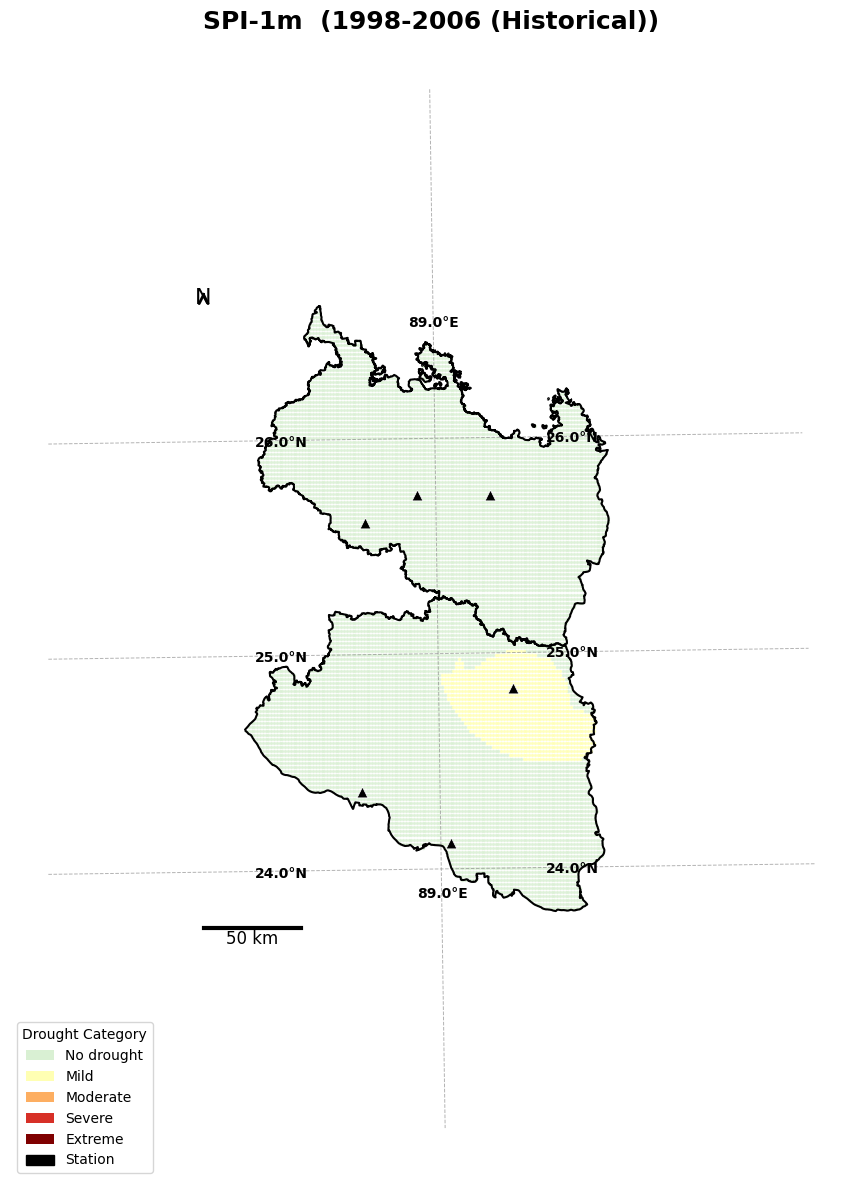

Saved: SPI_1m_2007-2015 (Historical).png


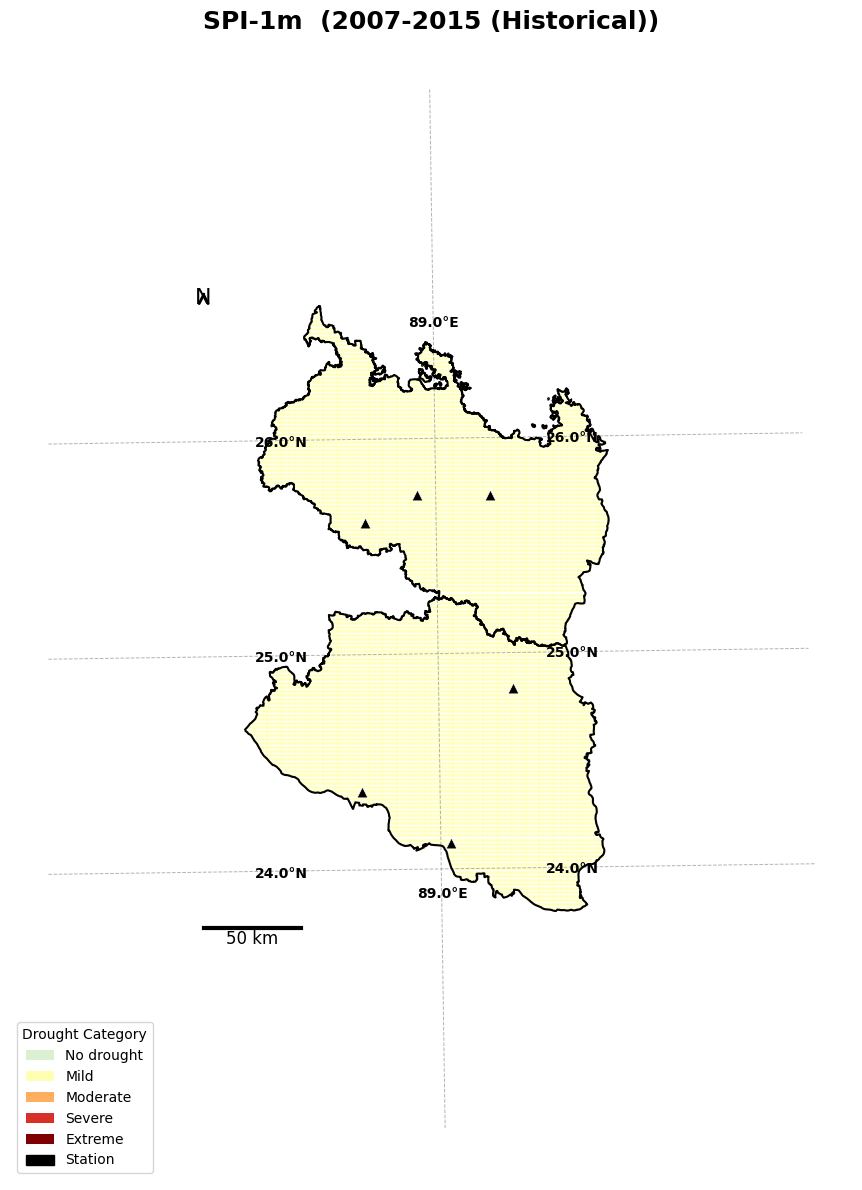

Saved: SPI_1m_2016-2023 (Historical - Recent).png


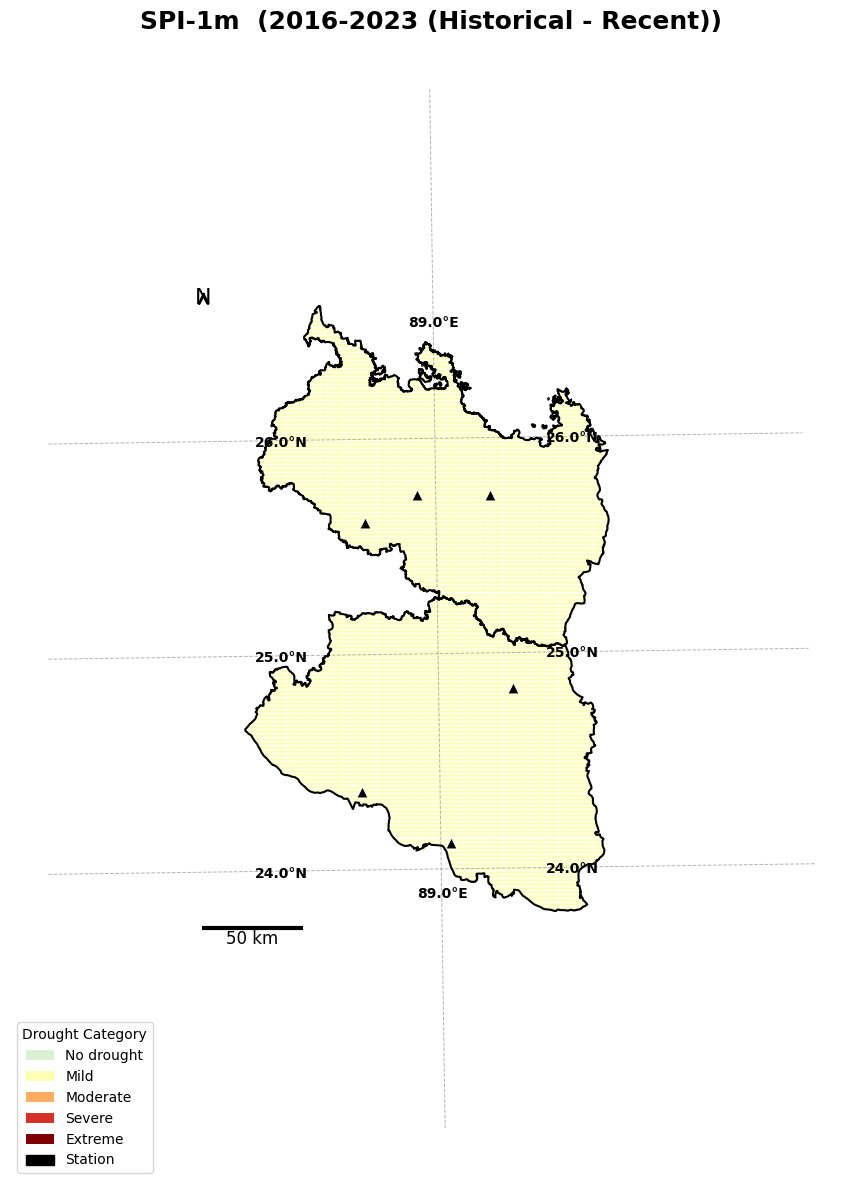

Saved: SPI_1m_2024-2050 (Forecast).png


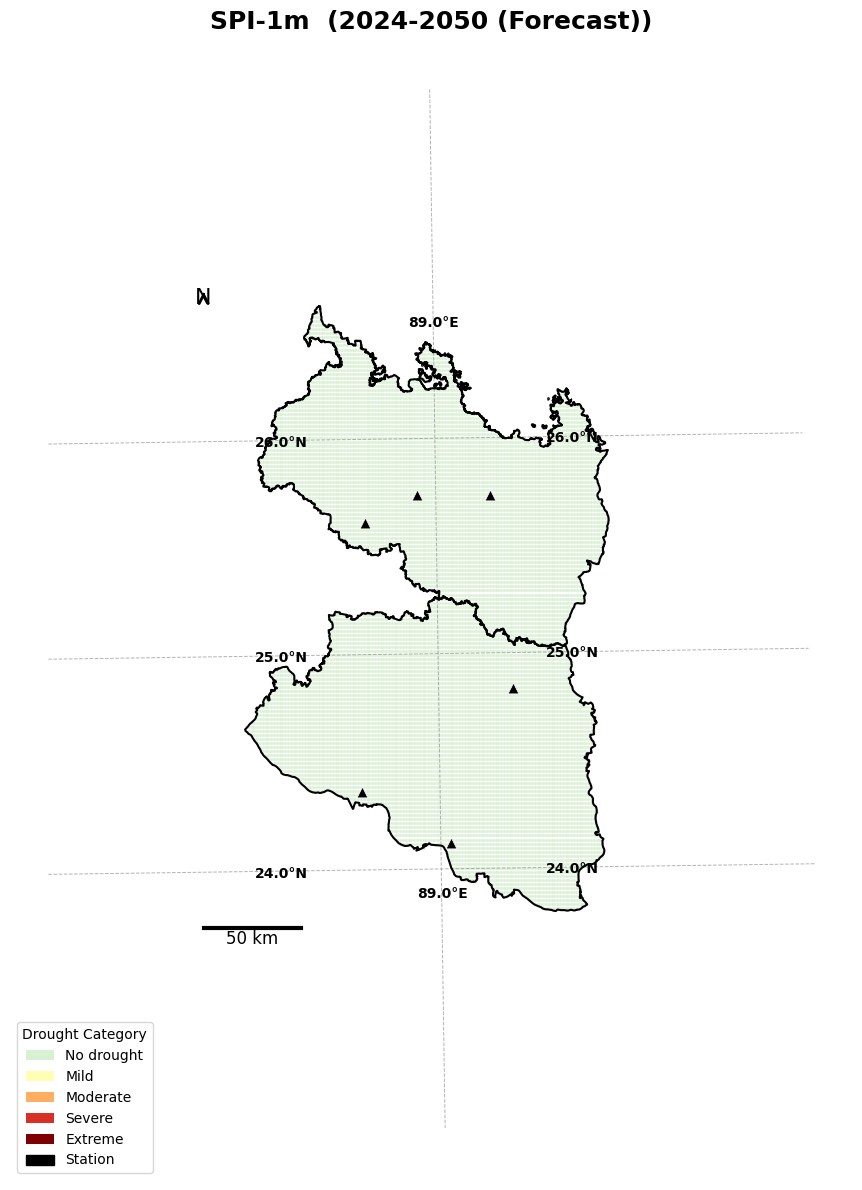

Saved: SPEI_1m_1998-2006 (Historical).png


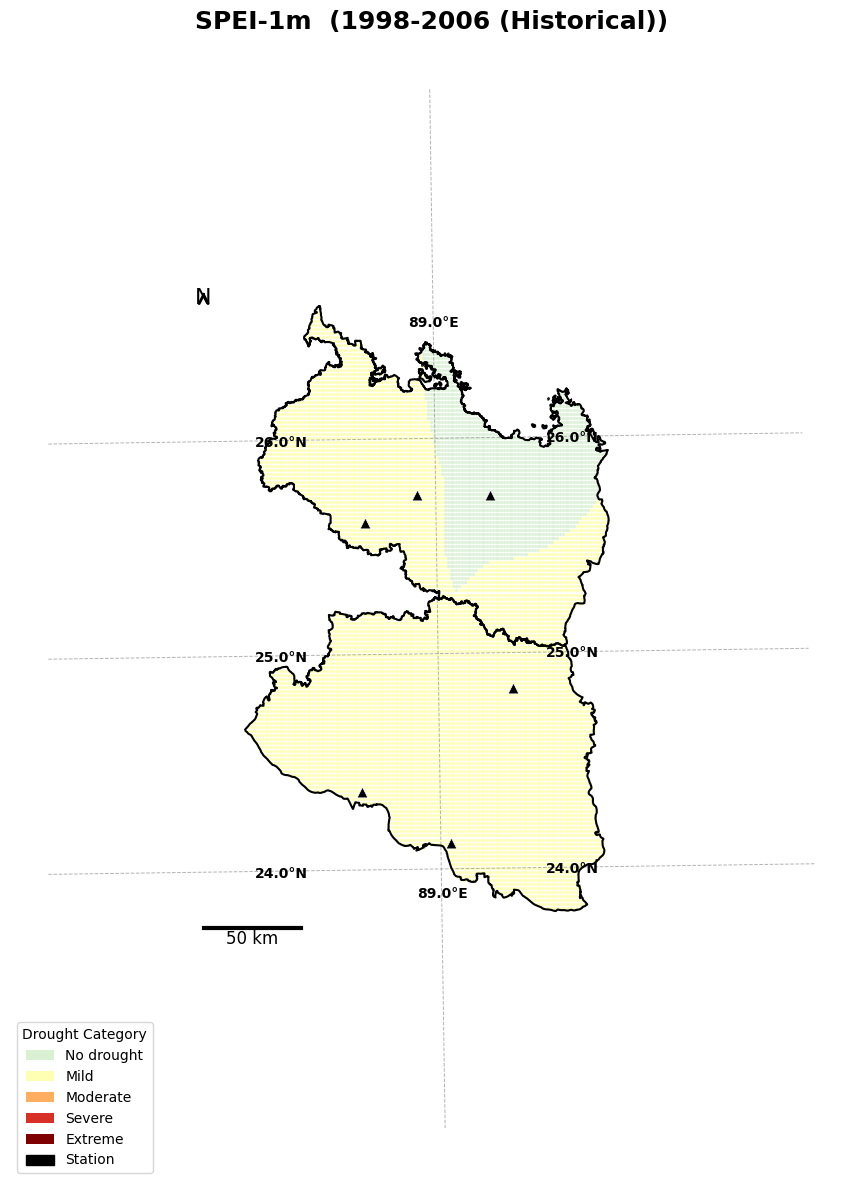

Saved: SPEI_1m_2007-2015 (Historical).png


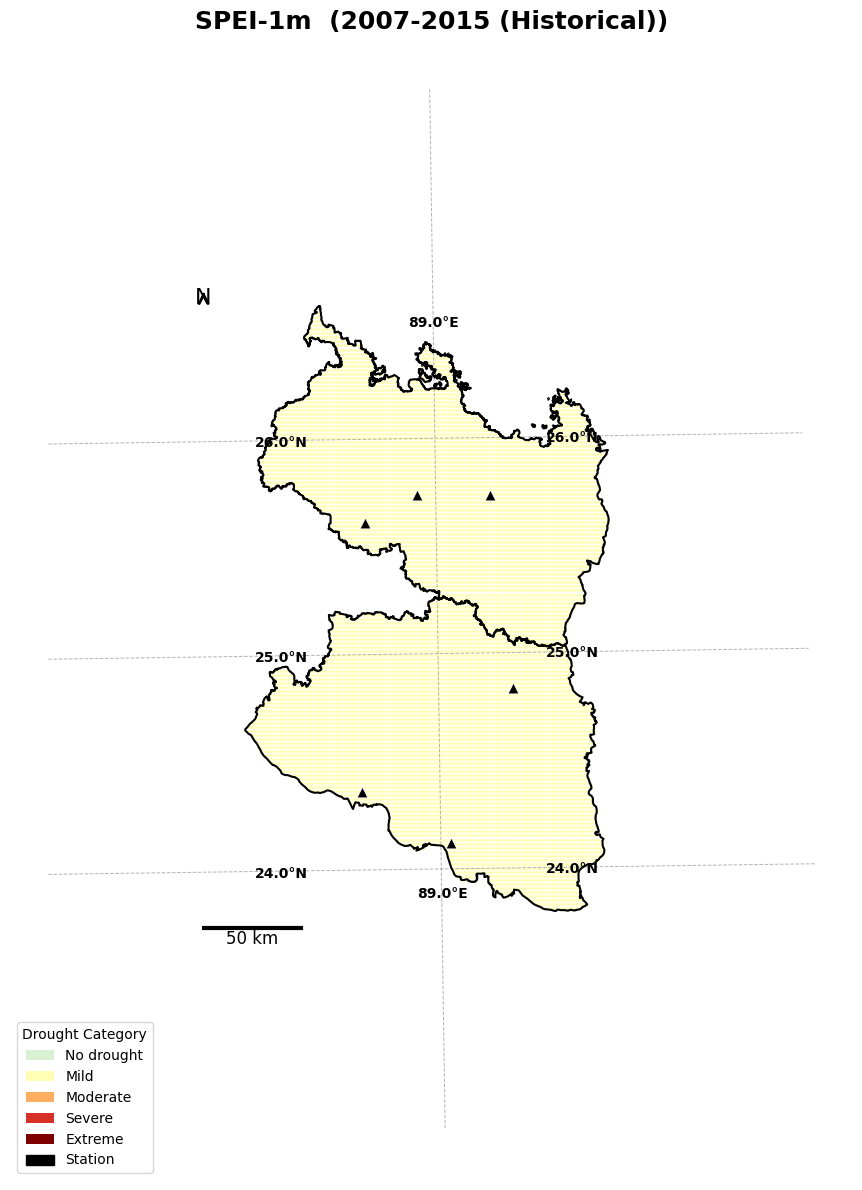

Saved: SPEI_1m_2016-2023 (Historical - Recent).png


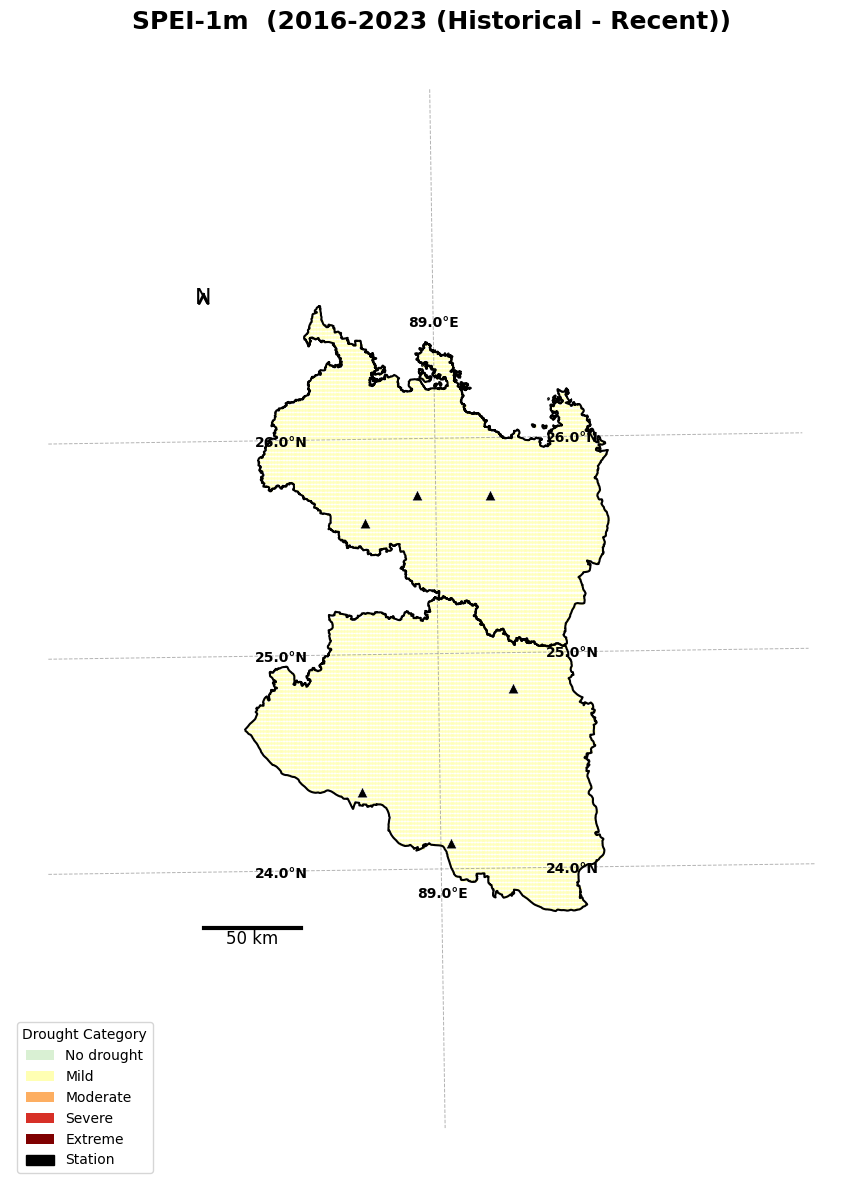

Saved: SPEI_1m_2024-2050 (Forecast).png


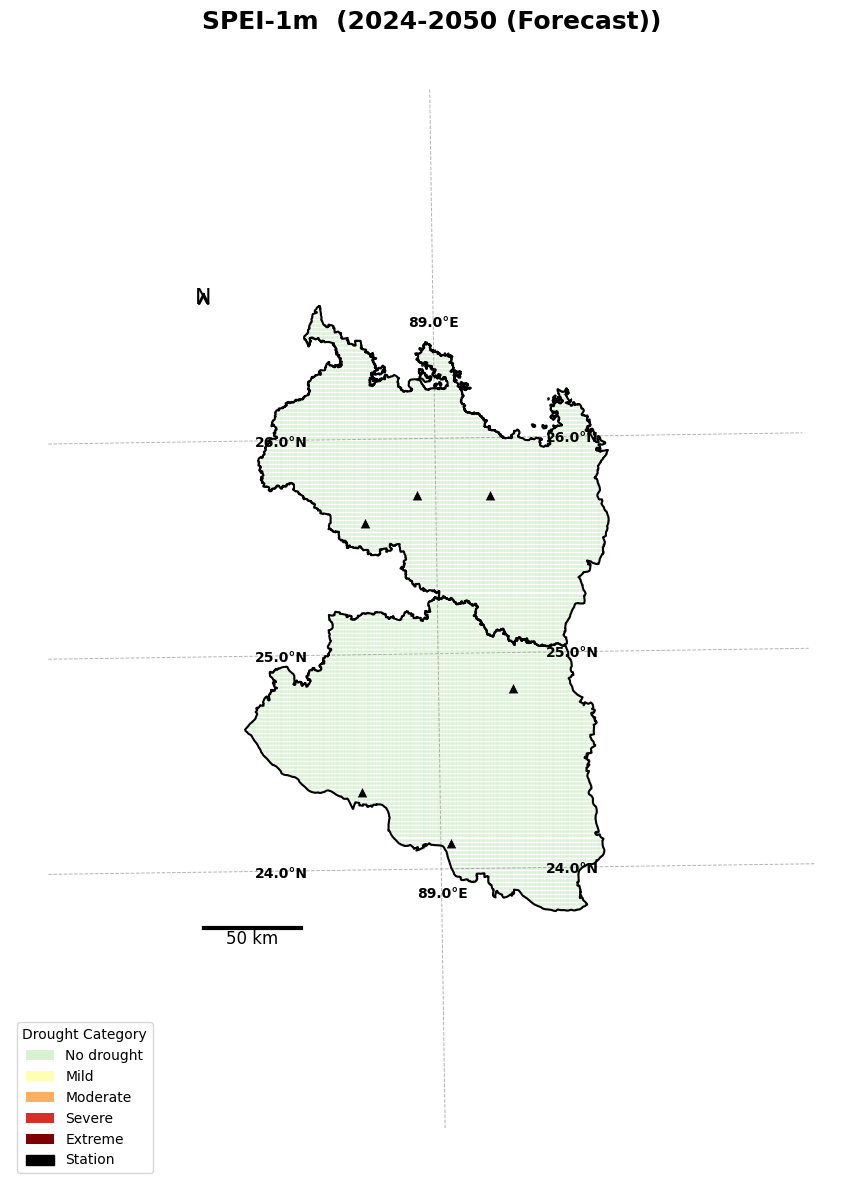

In [ ]:
# --- Single scale: 12 months only ---
periods = [
    '1998-2006 (Historical)',
    '2007-2015 (Historical)',
    '2016-2023 (Historical - Recent)',
    '2024-2050 (Forecast)'
]
period_labels = ['1998-2006', '2007-2015', '2016-2023', '2024-2050']
scales = [1]   # Change this to [1], [3], [6], or [24] as needed

for idx in ['SPI', 'SPEI']:
    for scale in scales:
        for period_label, period_full in zip(period_labels, periods):
            produce_drought_map(idx, scale, period_full, None, None)

Saved: SPI_3m_1998-2006 (Historical).png


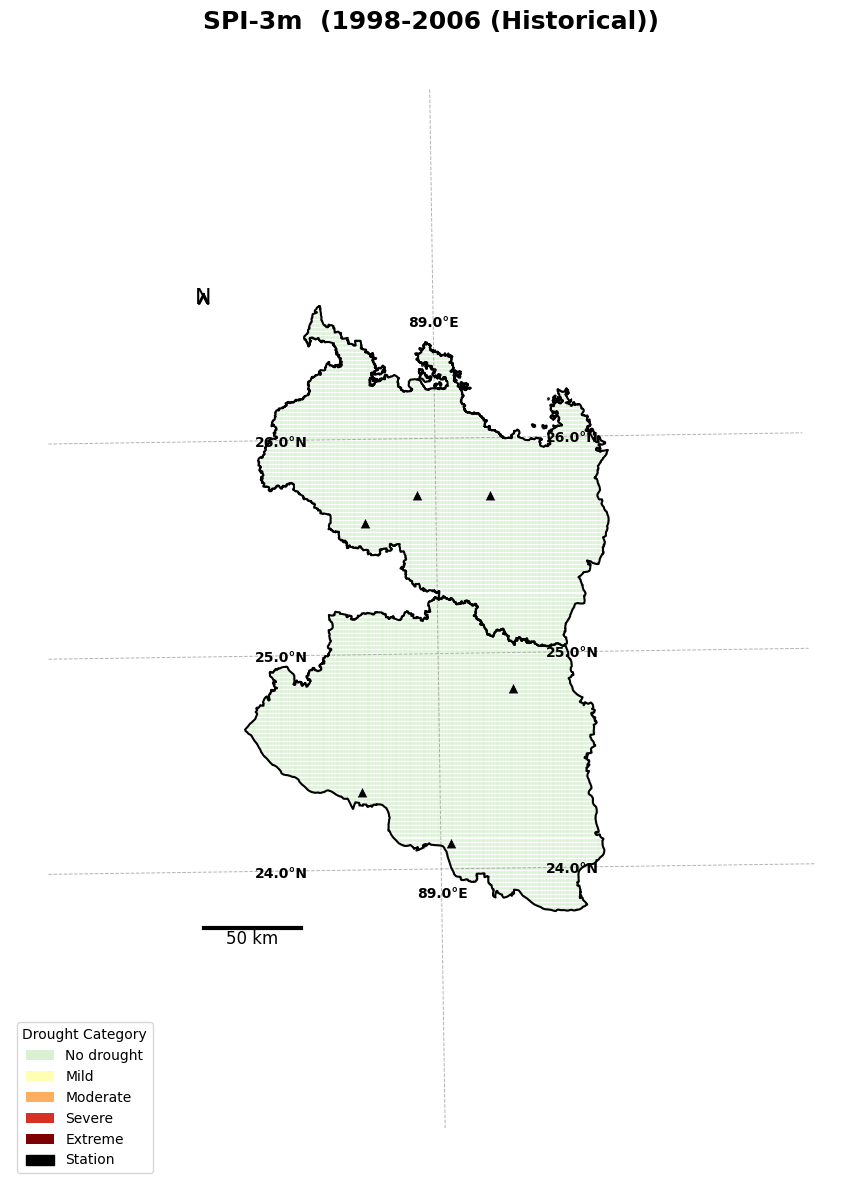

Saved: SPI_3m_2007-2015 (Historical).png


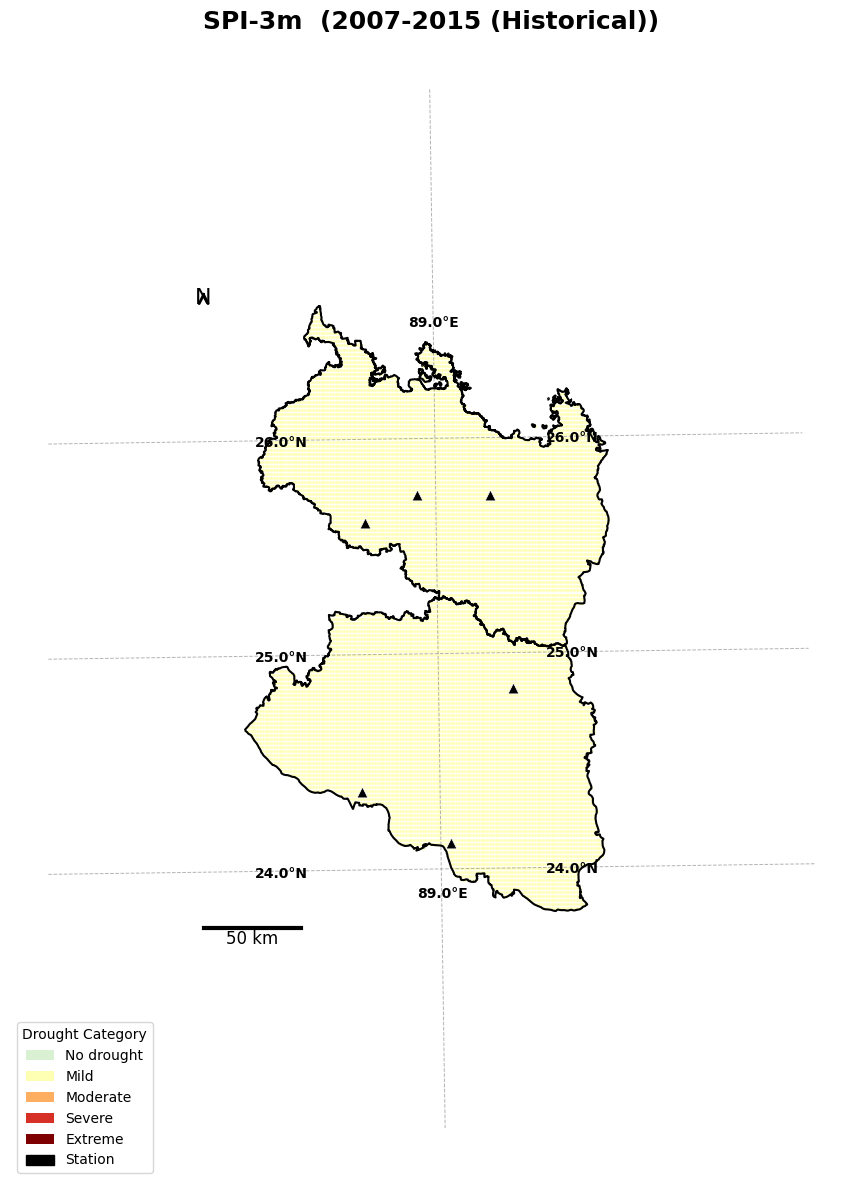

Saved: SPI_3m_2016-2023 (Historical - Recent).png


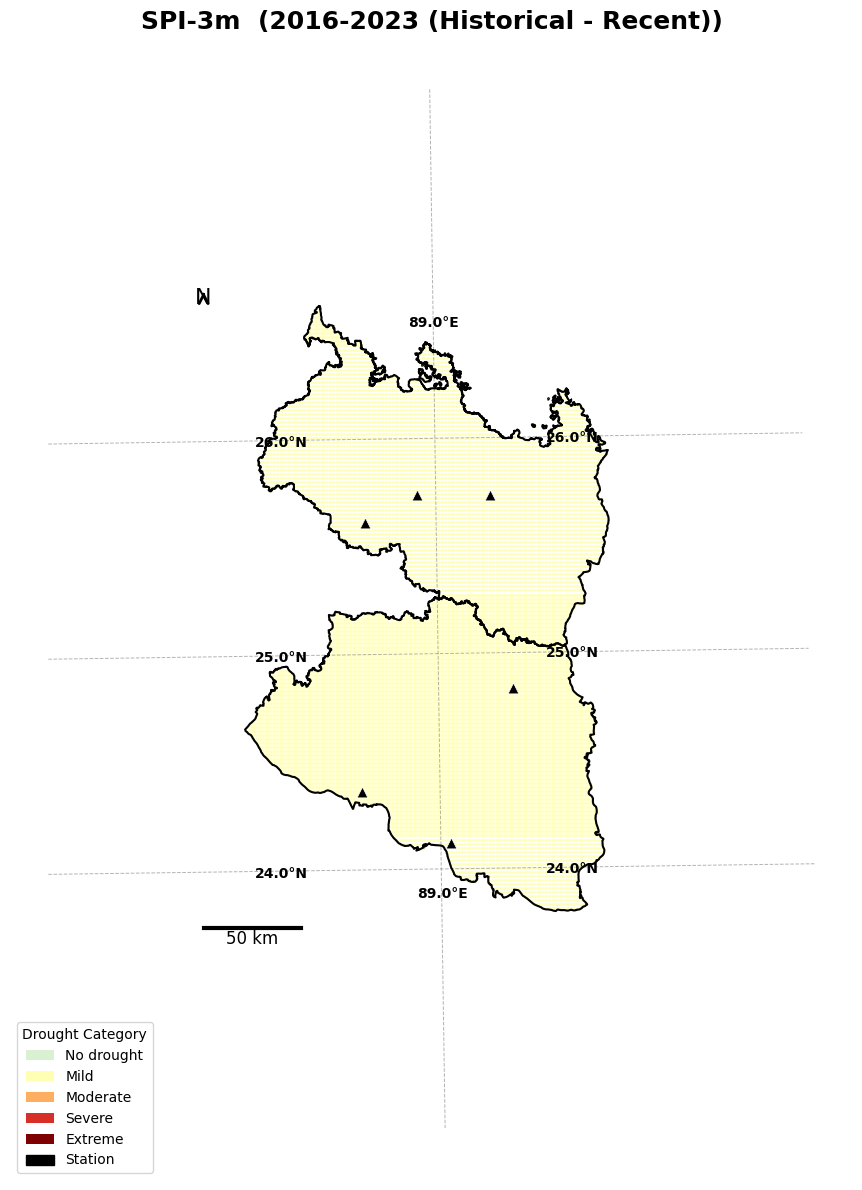

Saved: SPI_3m_2024-2050 (Forecast).png


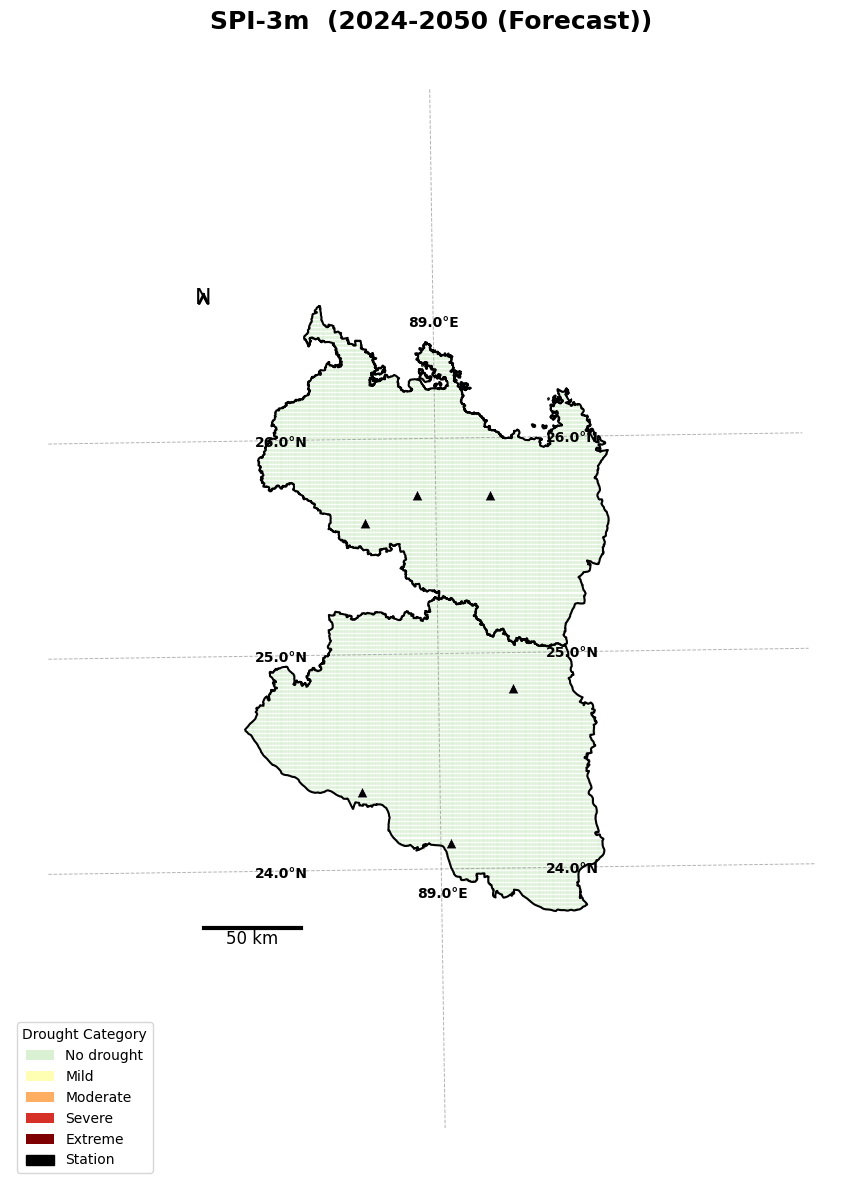

Saved: SPEI_3m_1998-2006 (Historical).png


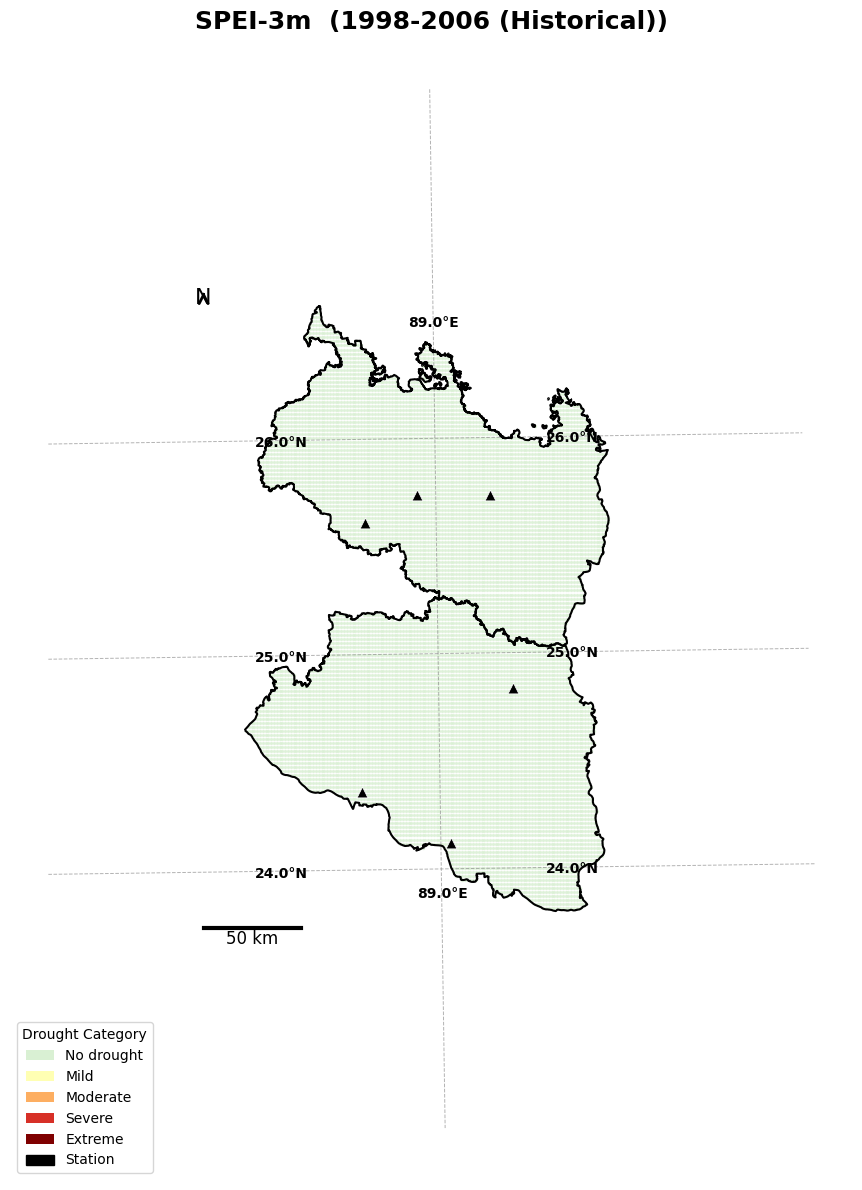

Saved: SPEI_3m_2007-2015 (Historical).png


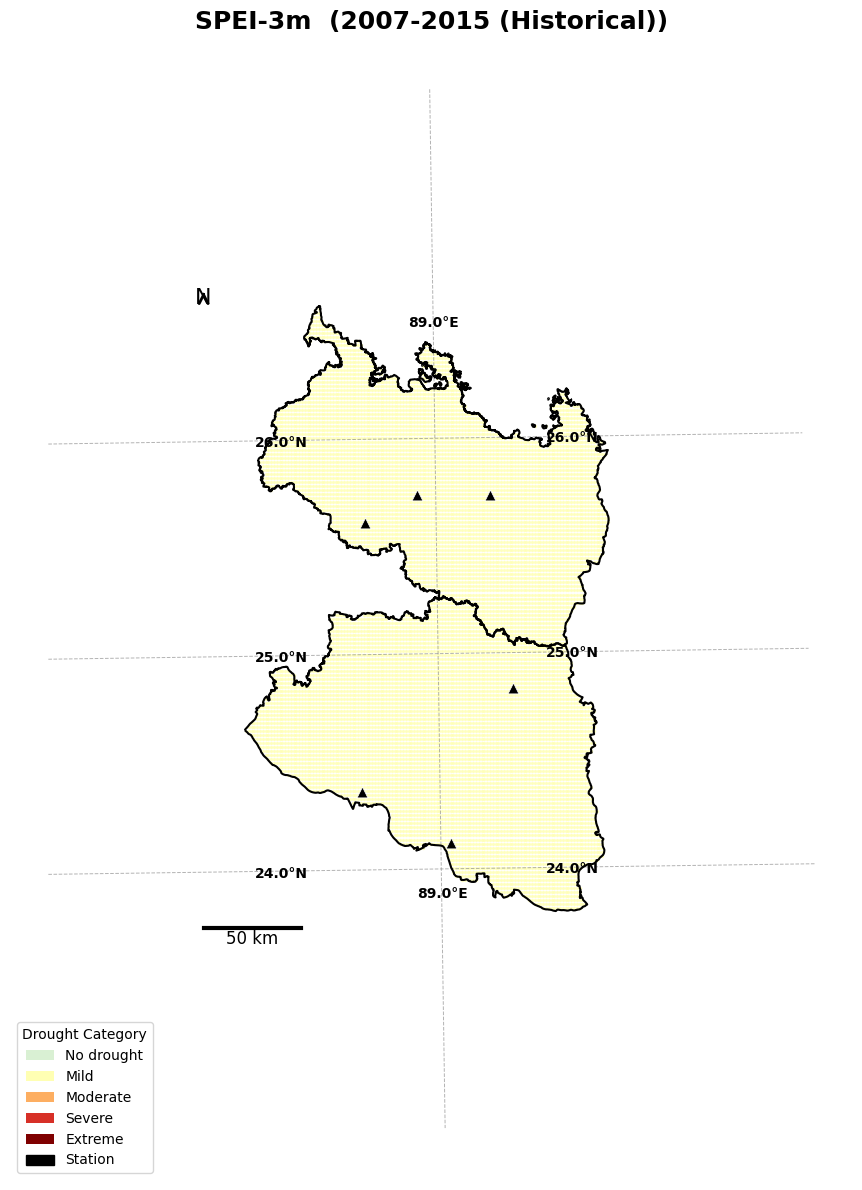

Saved: SPEI_3m_2016-2023 (Historical - Recent).png


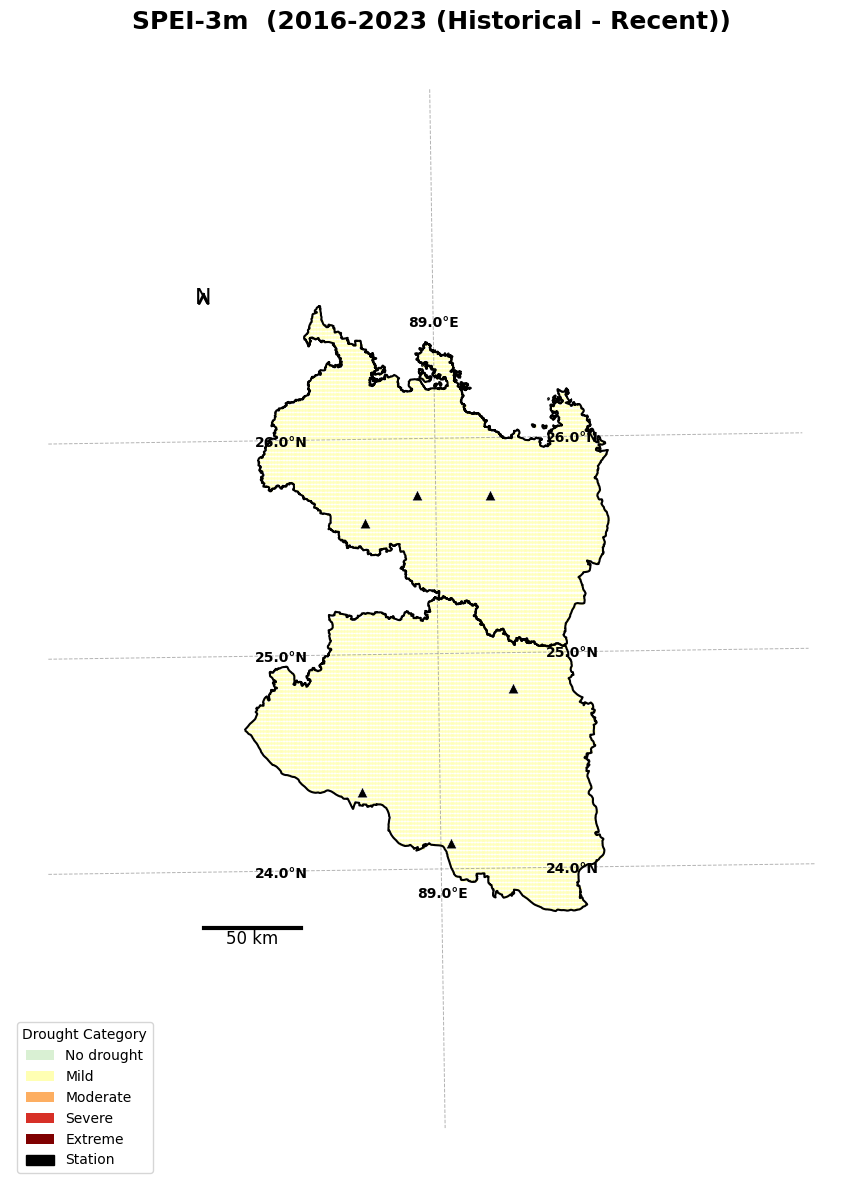

Saved: SPEI_3m_2024-2050 (Forecast).png


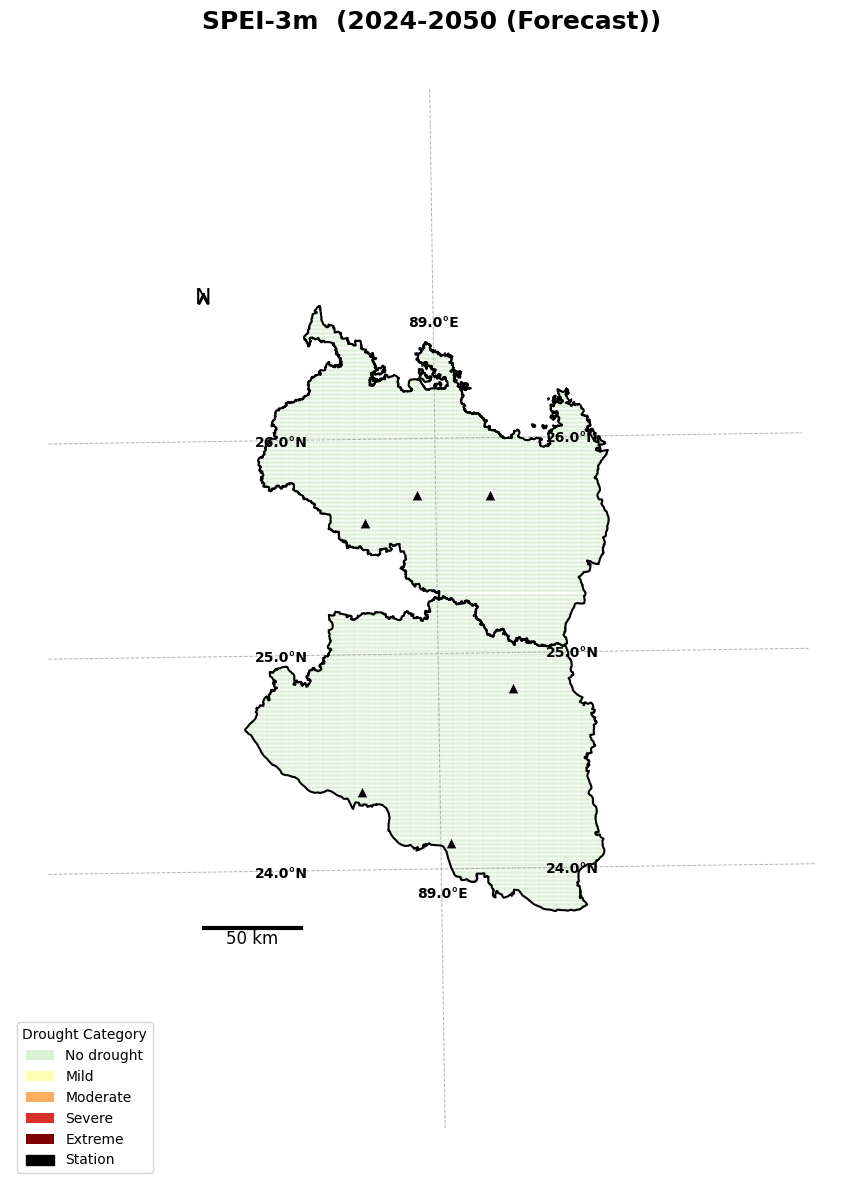

In [ ]:
# --- Single scale: 12 months only ---
periods = [
    '1998-2006 (Historical)',
    '2007-2015 (Historical)',
    '2016-2023 (Historical - Recent)',
    '2024-2050 (Forecast)'
]
period_labels = ['1998-2006', '2007-2015', '2016-2023', '2024-2050']
scales = [3]   # Change this to [1], [3], [6], or [24] as needed

for idx in ['SPI', 'SPEI']:
    for scale in scales:
        for period_label, period_full in zip(period_labels, periods):
            produce_drought_map(idx, scale, period_full, None, None)

Saved: SPI_6m_1998-2006 (Historical).png


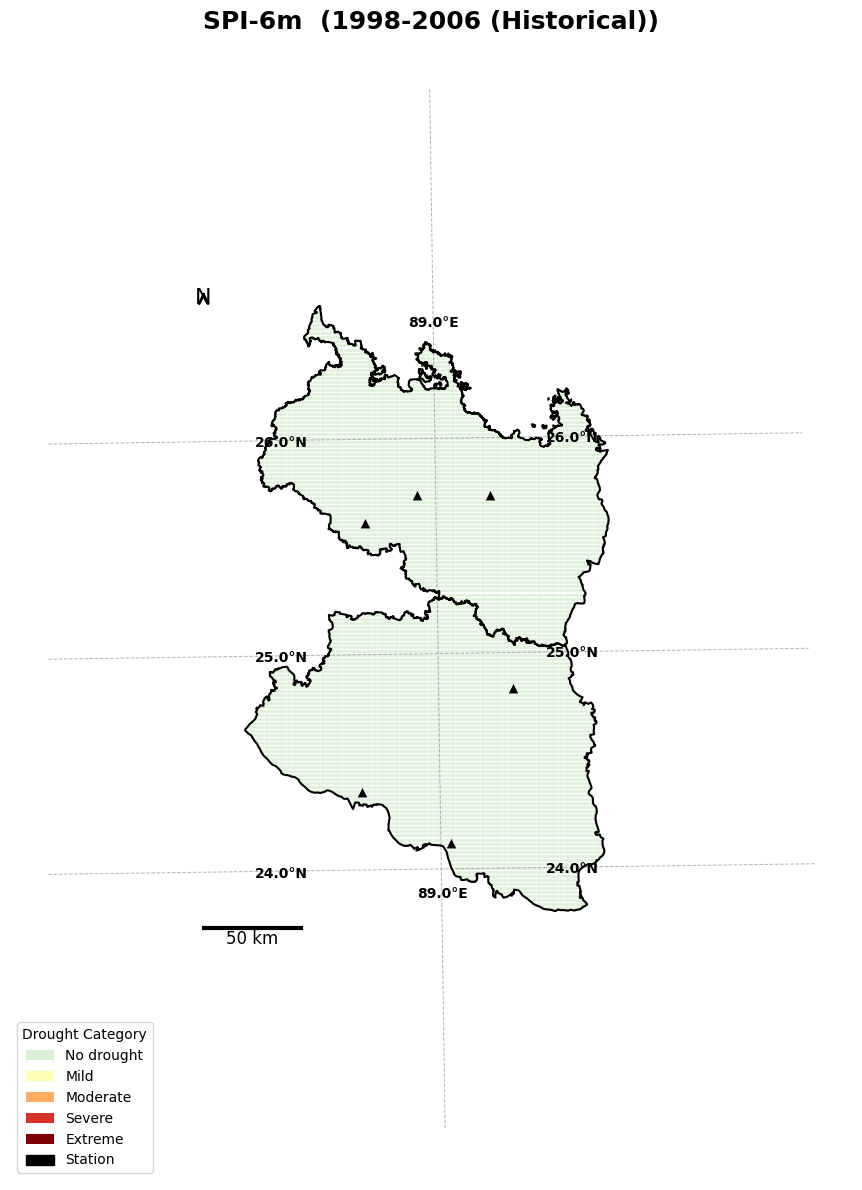

Saved: SPI_6m_2007-2015 (Historical).png


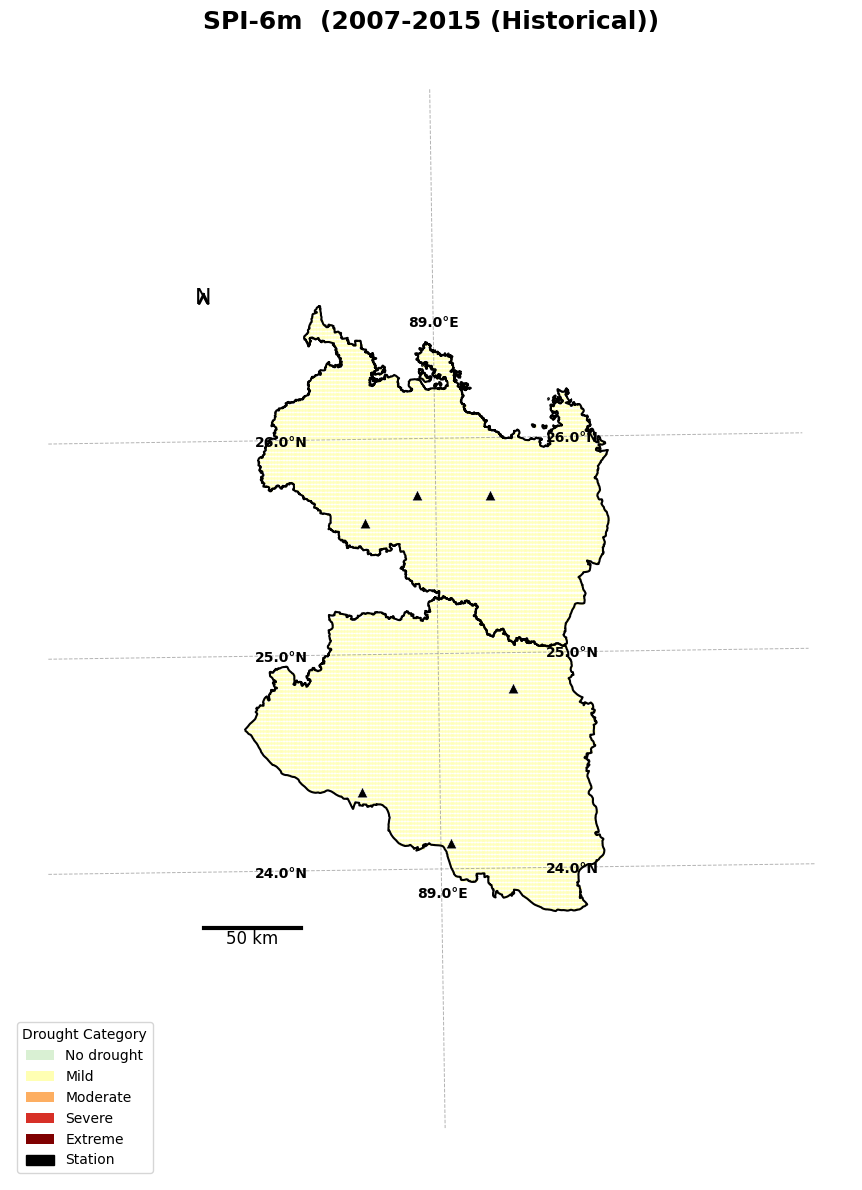

Saved: SPI_6m_2016-2023 (Historical - Recent).png


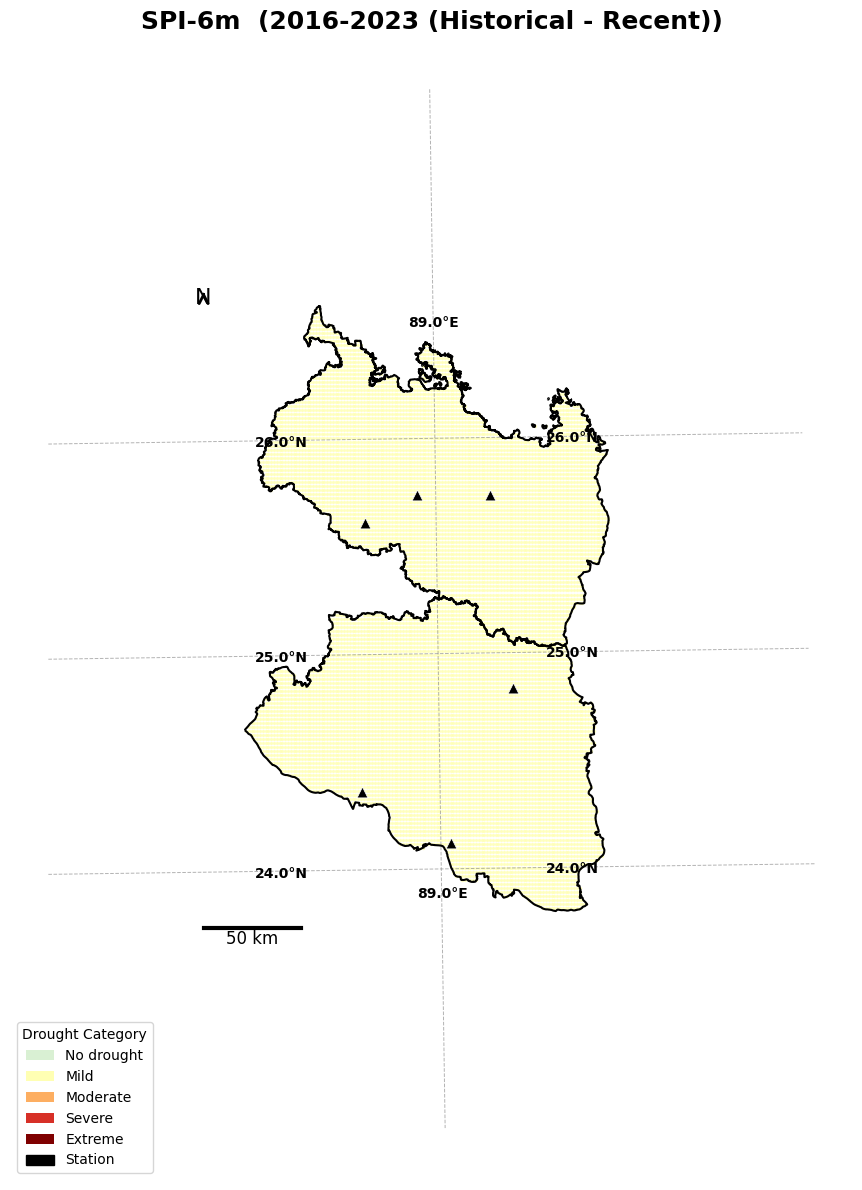

Saved: SPI_6m_2024-2050 (Forecast).png


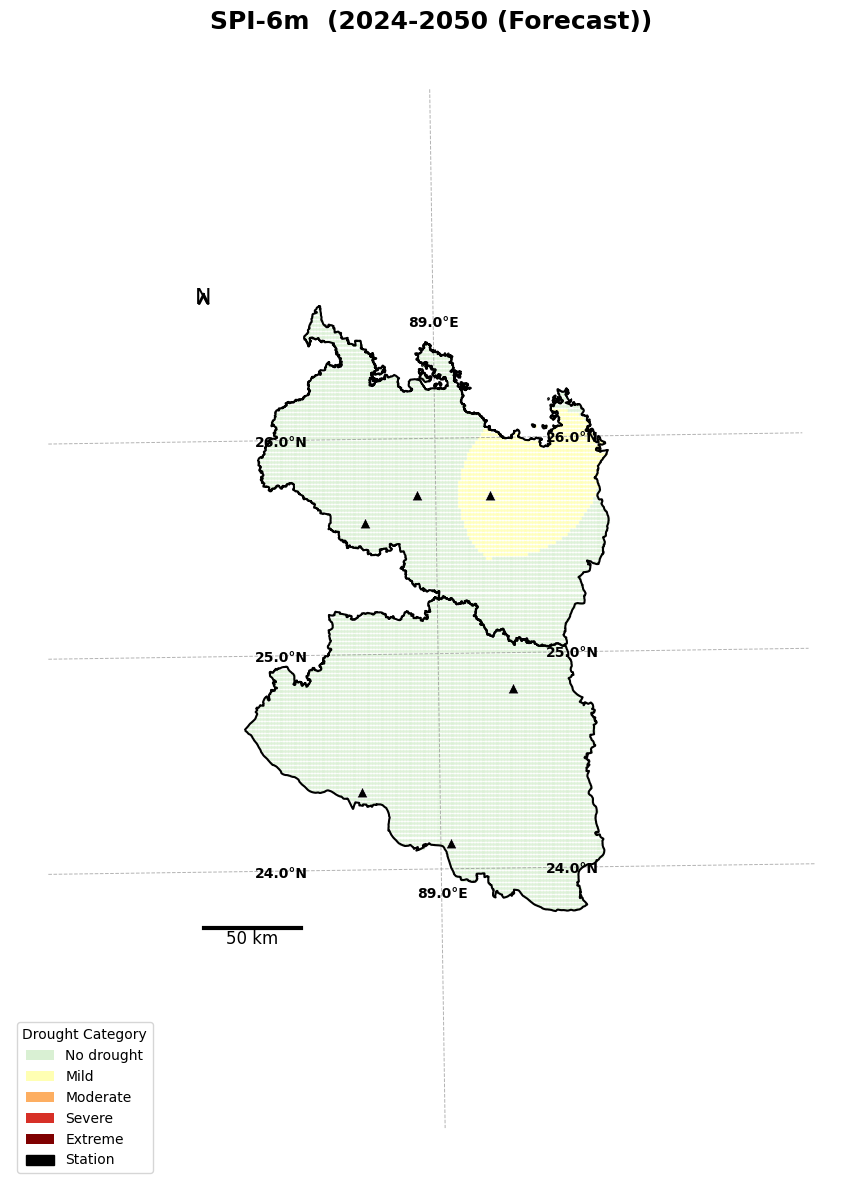

Saved: SPEI_6m_1998-2006 (Historical).png


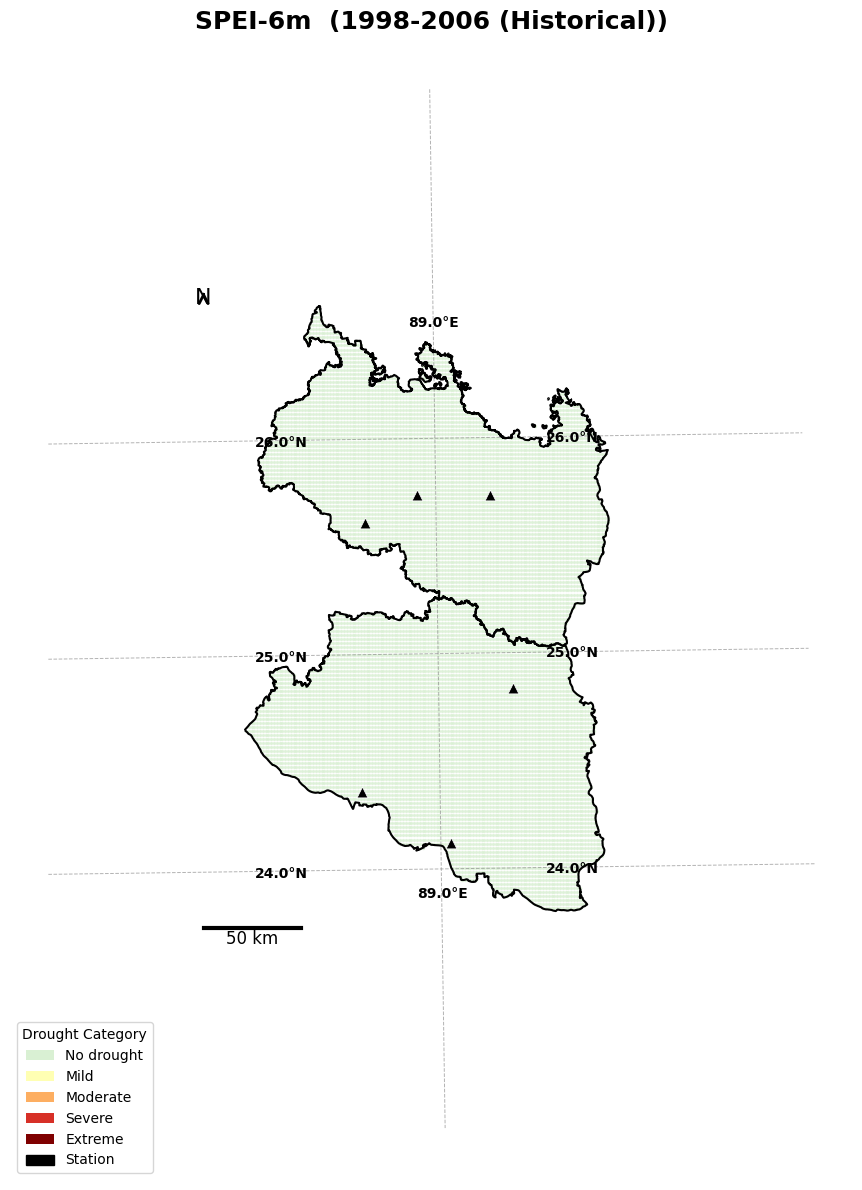

Saved: SPEI_6m_2007-2015 (Historical).png


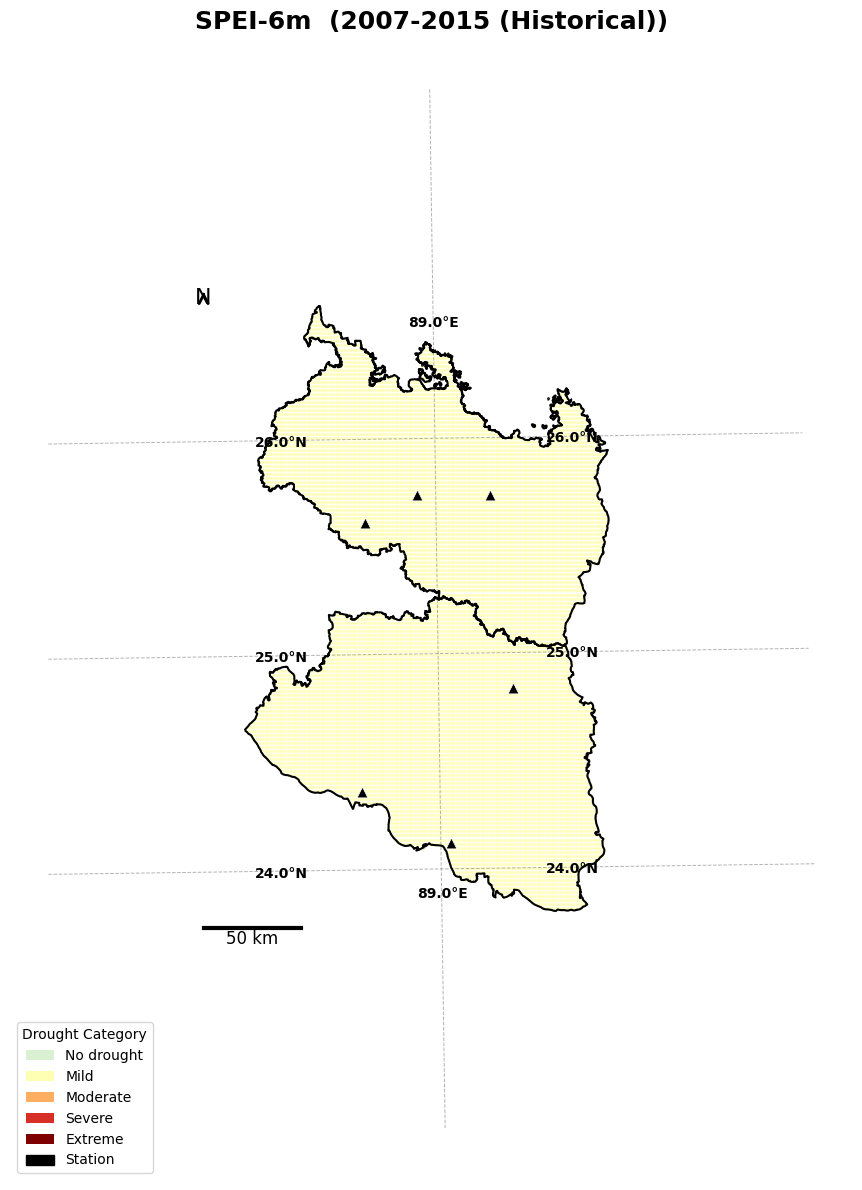

Saved: SPEI_6m_2016-2023 (Historical - Recent).png


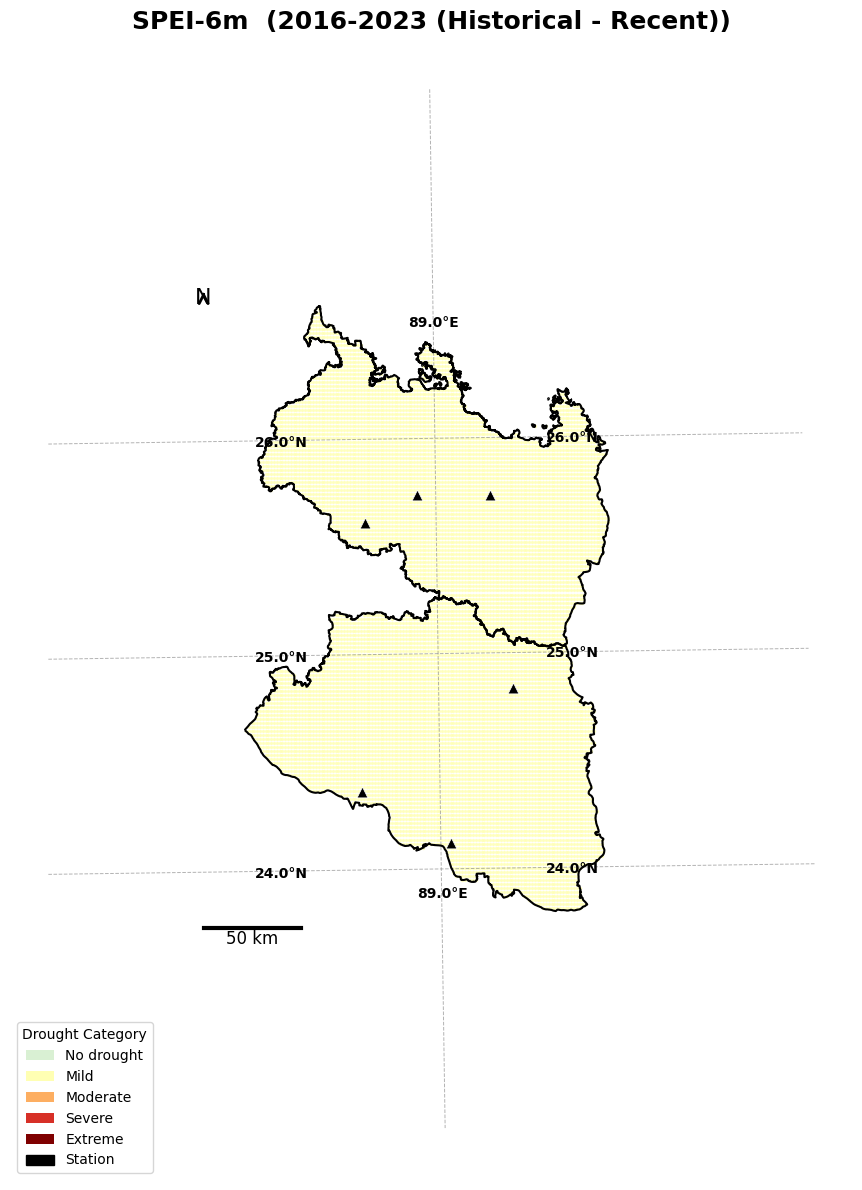

Saved: SPEI_6m_2024-2050 (Forecast).png


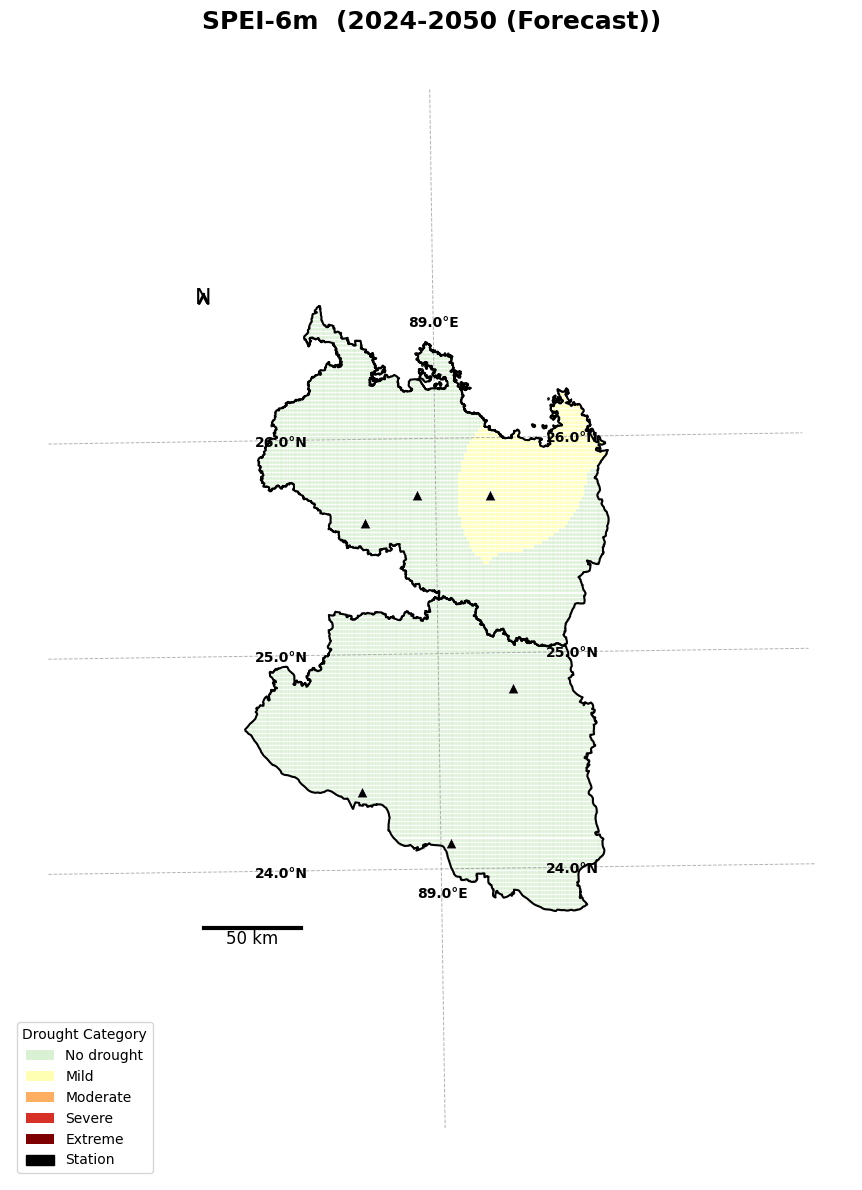

In [ ]:
# --- Single scale: 12 months only ---
periods = [
    '1998-2006 (Historical)',
    '2007-2015 (Historical)',
    '2016-2023 (Historical - Recent)',
    '2024-2050 (Forecast)'
]
period_labels = ['1998-2006', '2007-2015', '2016-2023', '2024-2050']
scales = [6]   # Change this to [1], [3], [6], or [24] as needed

for idx in ['SPI', 'SPEI']:
    for scale in scales:
        for period_label, period_full in zip(period_labels, periods):
            produce_drought_map(idx, scale, period_full, None, None)

Saved: SPI_12m_1998-2006 (Historical).png


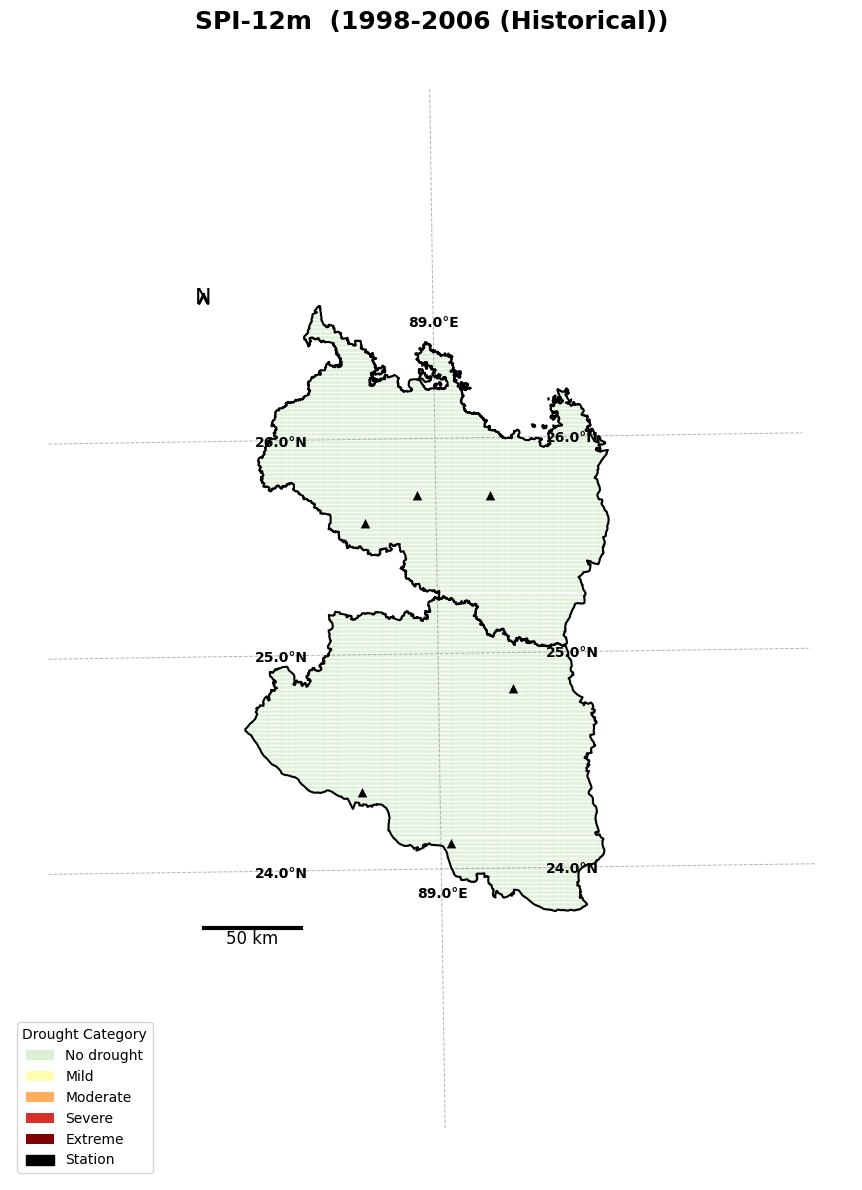

Saved: SPI_12m_2007-2015 (Historical).png


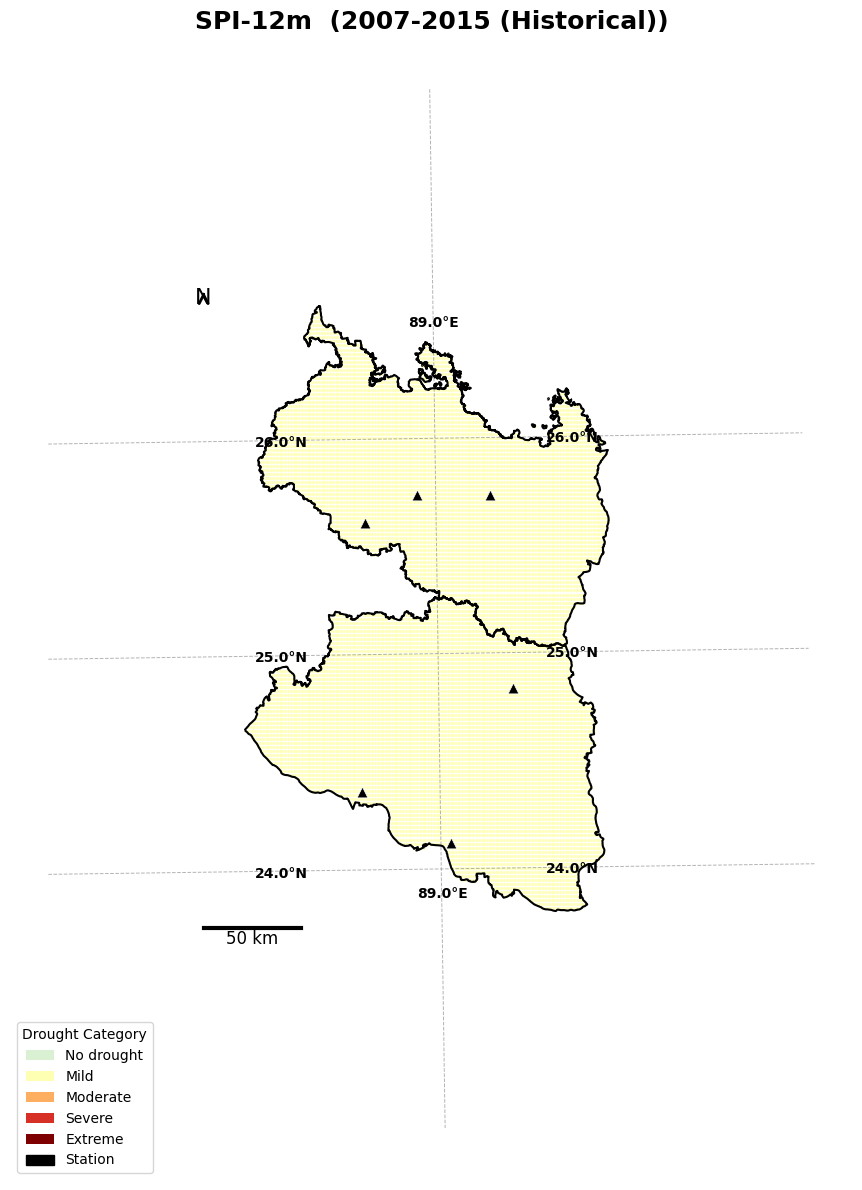

Saved: SPI_12m_2016-2023 (Historical - Recent).png


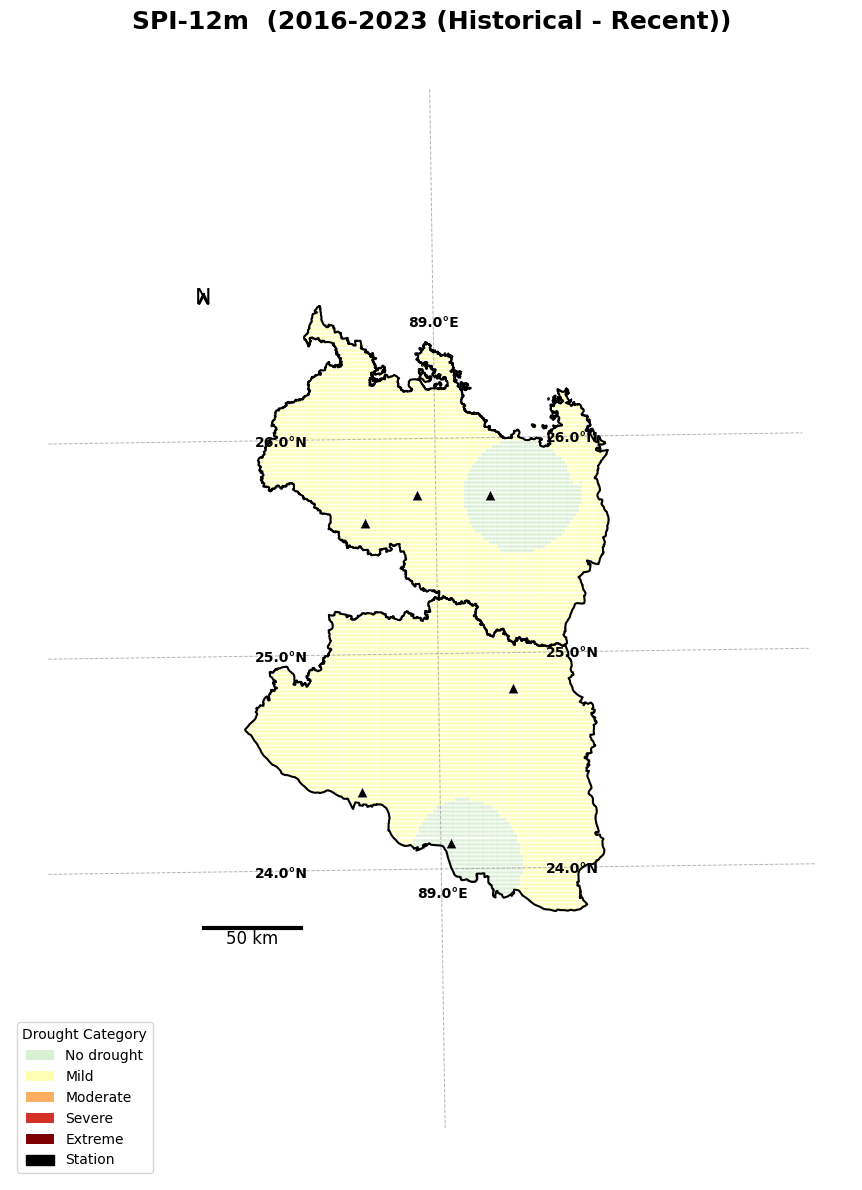

Saved: SPI_12m_2024-2050 (Forecast).png


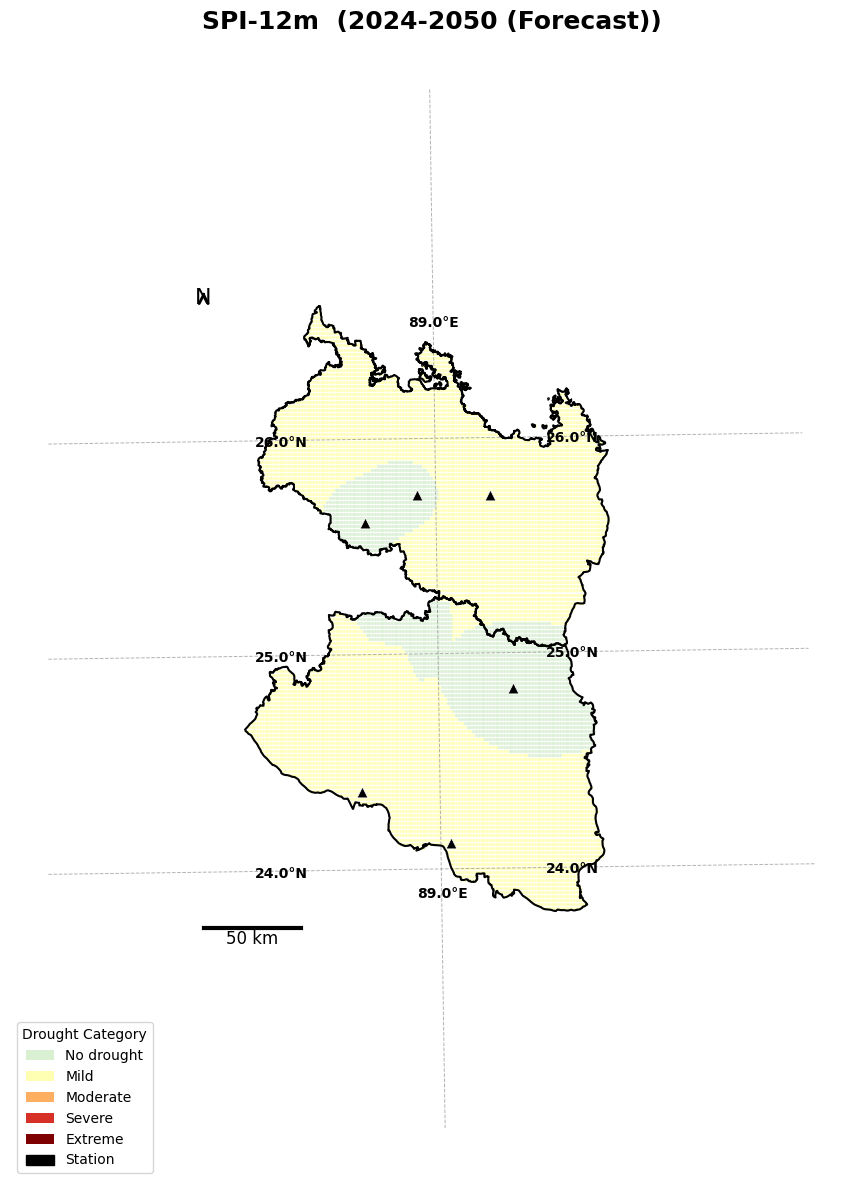

Saved: SPEI_12m_1998-2006 (Historical).png


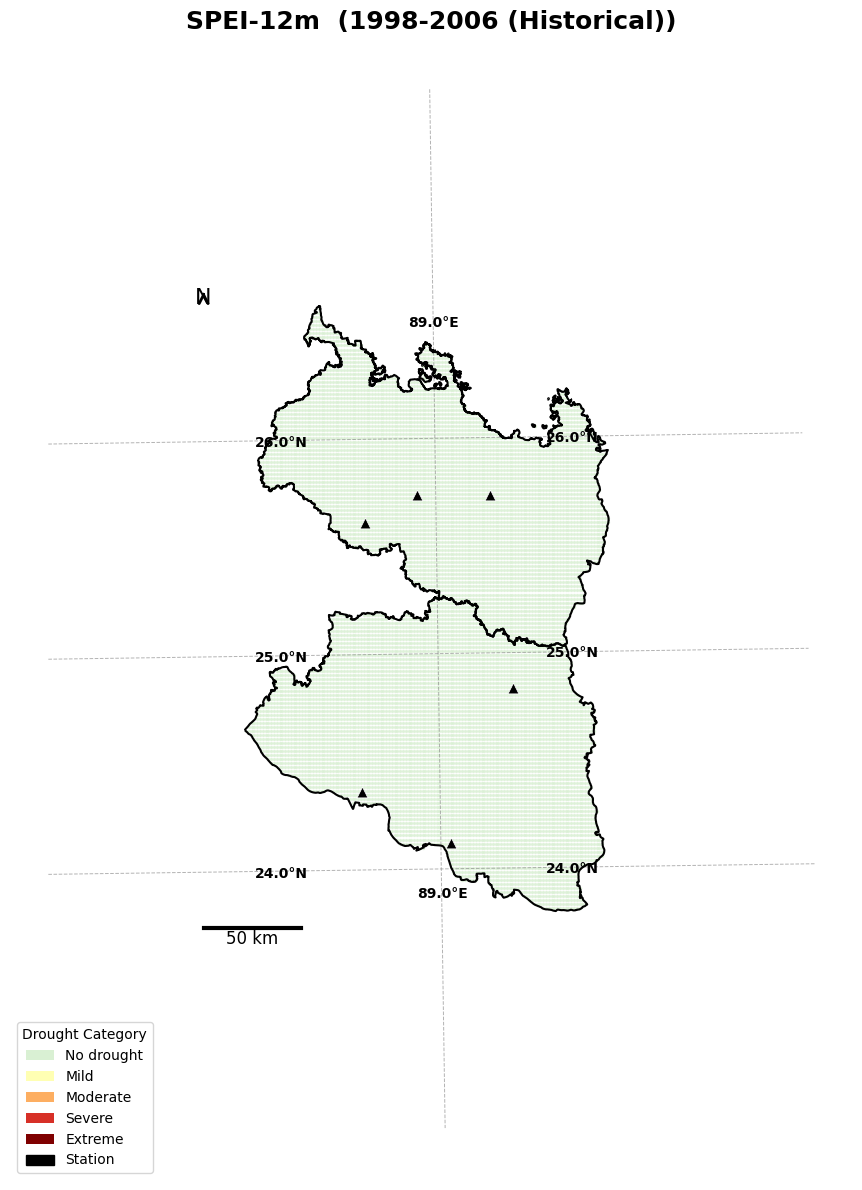

Saved: SPEI_12m_2007-2015 (Historical).png


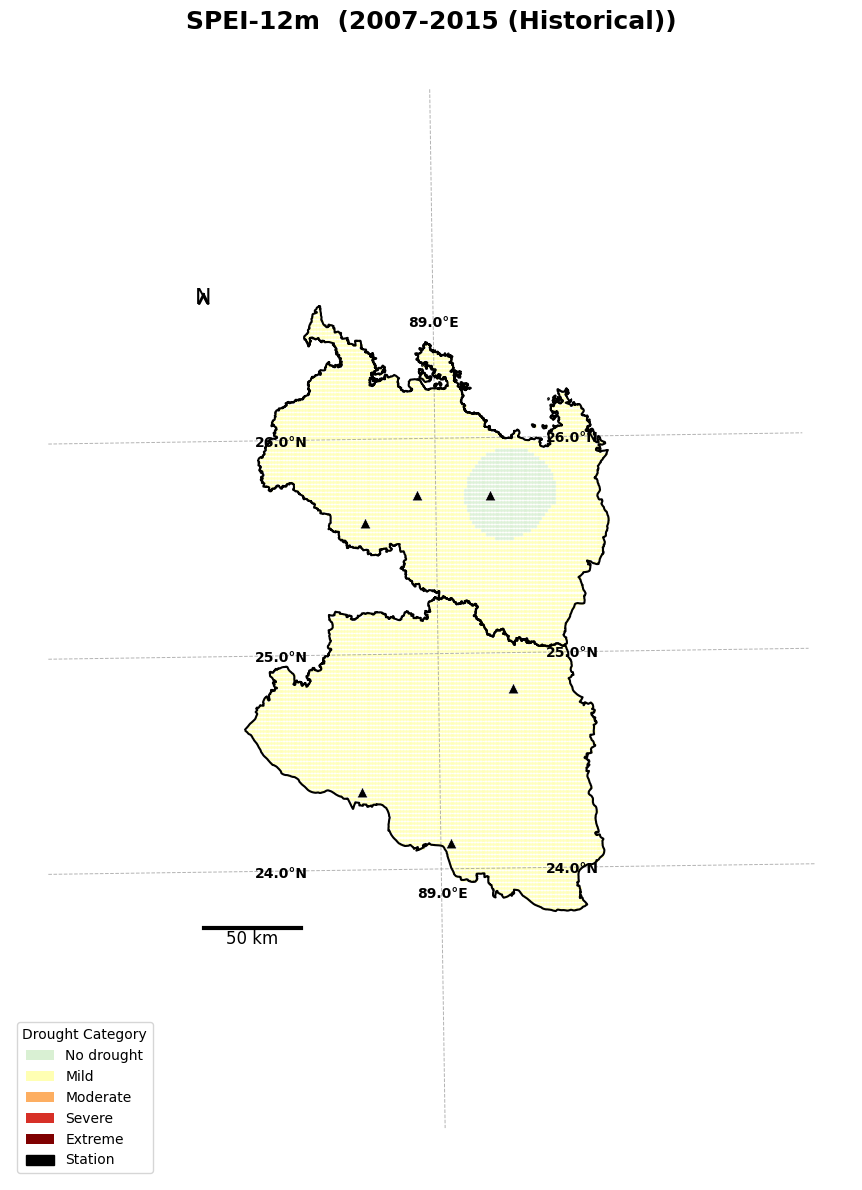

Saved: SPEI_12m_2016-2023 (Historical - Recent).png


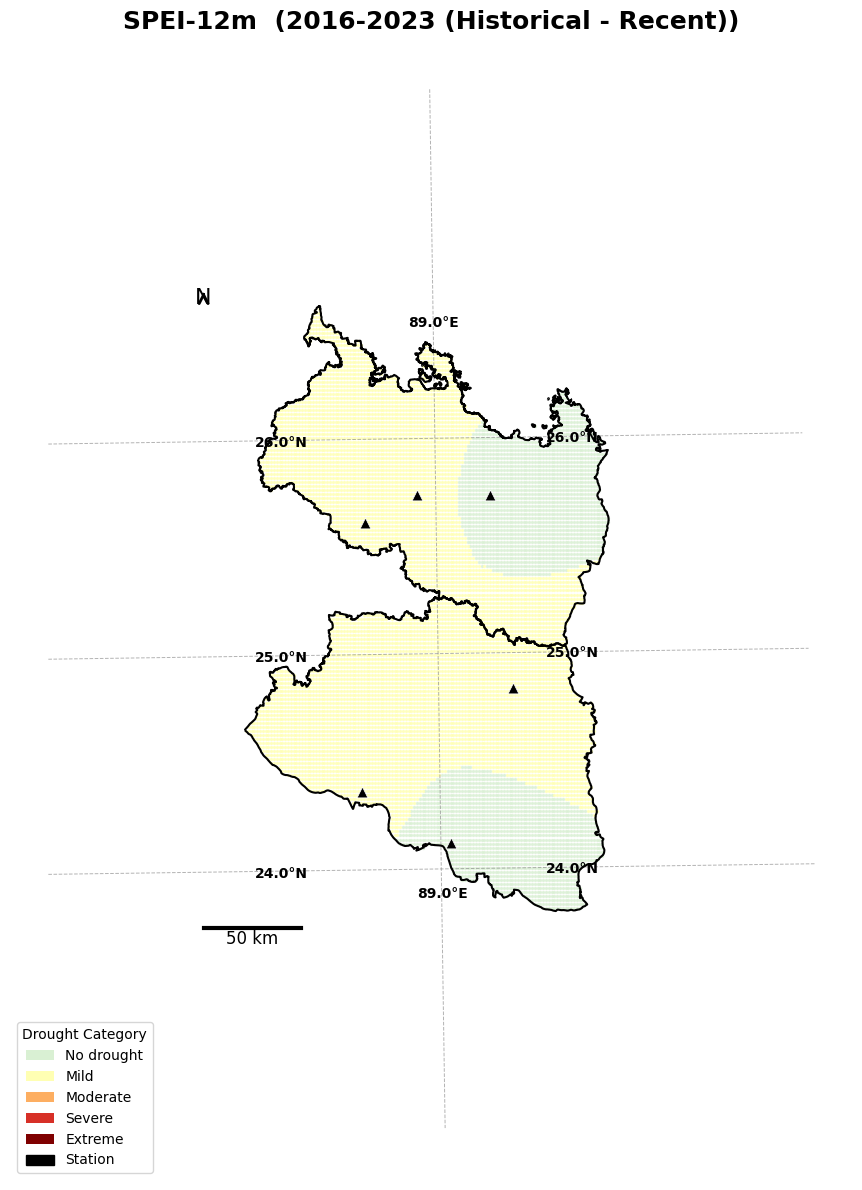

Saved: SPEI_12m_2024-2050 (Forecast).png


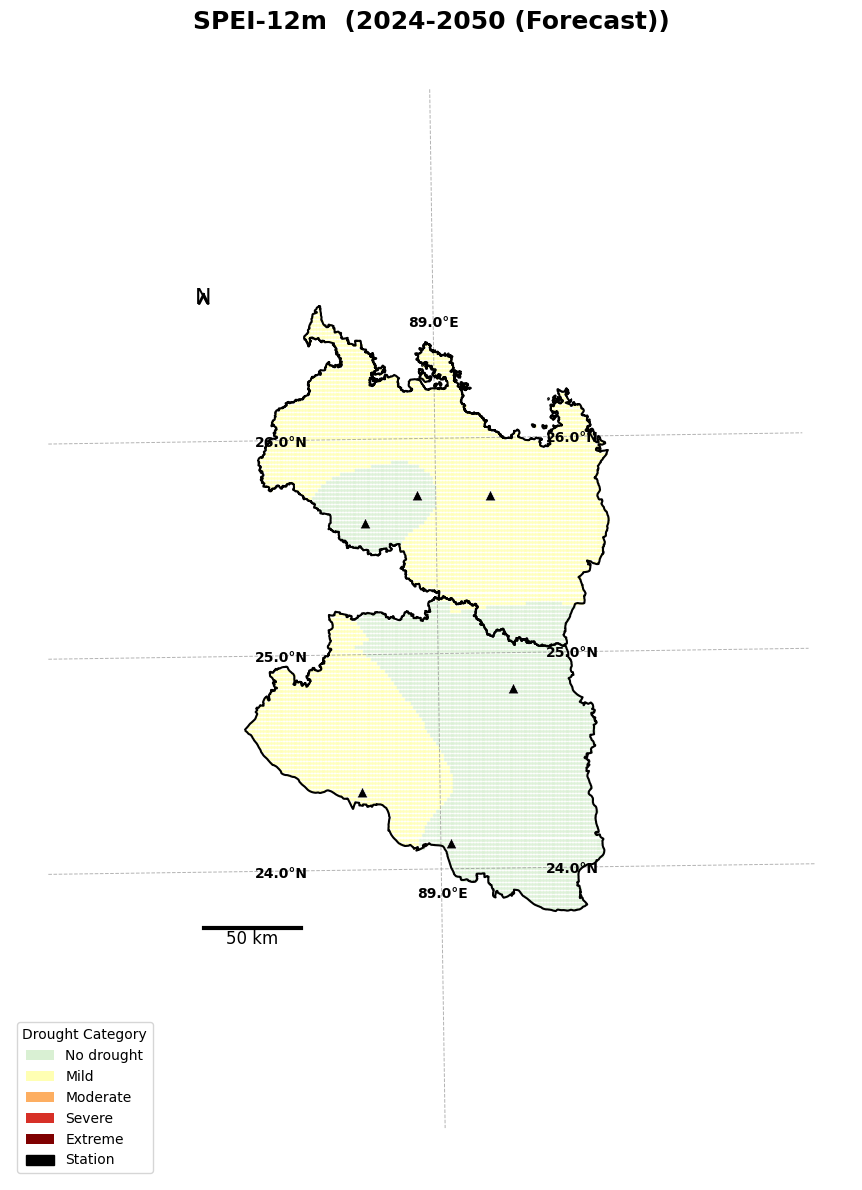

In [ ]:
# --- Single scale: 12 months only ---
periods = [
    '1998-2006 (Historical)',
    '2007-2015 (Historical)',
    '2016-2023 (Historical - Recent)',
    '2024-2050 (Forecast)'
]
period_labels = ['1998-2006', '2007-2015', '2016-2023', '2024-2050']
scales = [12]   # Change this to [1], [3], [6], or [24] as needed

for idx in ['SPI', 'SPEI']:
    for scale in scales:
        for period_label, period_full in zip(period_labels, periods):
            produce_drought_map(idx, scale, period_full, None, None)

Saved: SPI_24m_1998-2006 (Historical).png


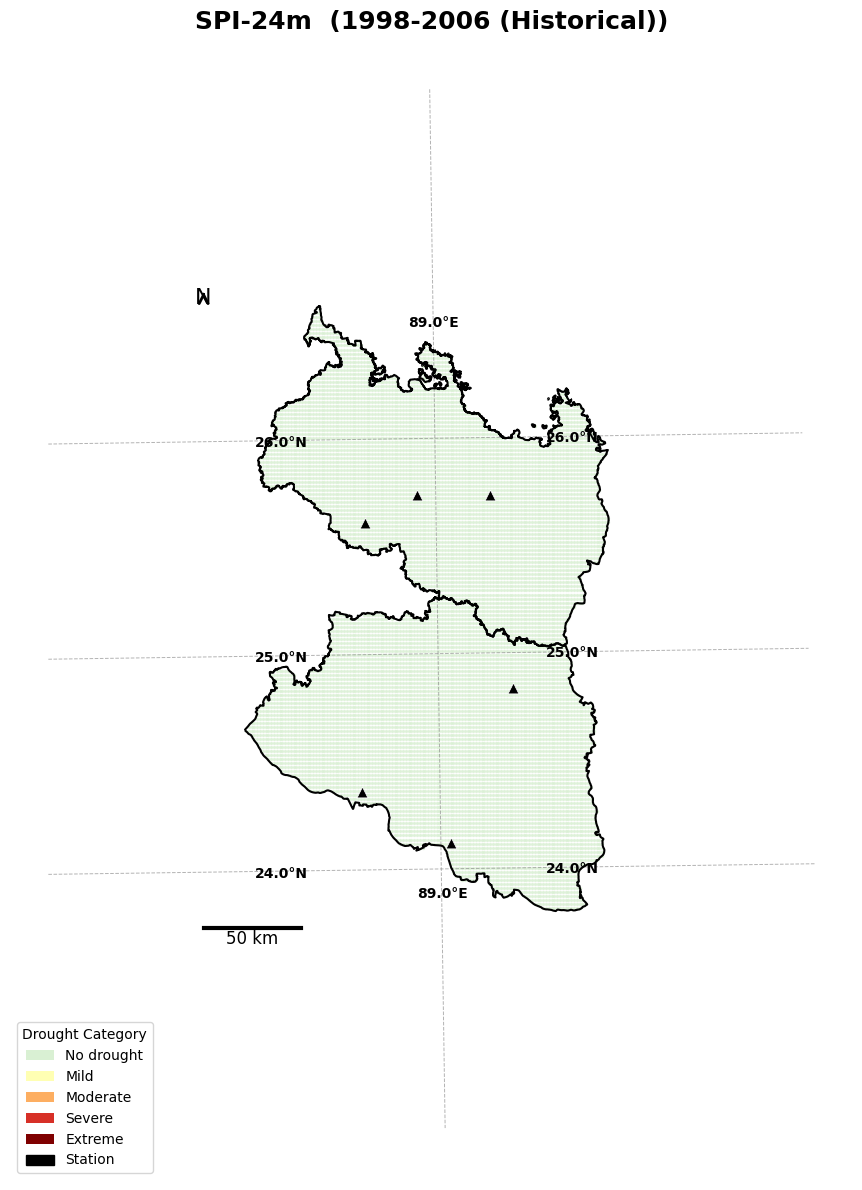

Saved: SPI_24m_2007-2015 (Historical).png


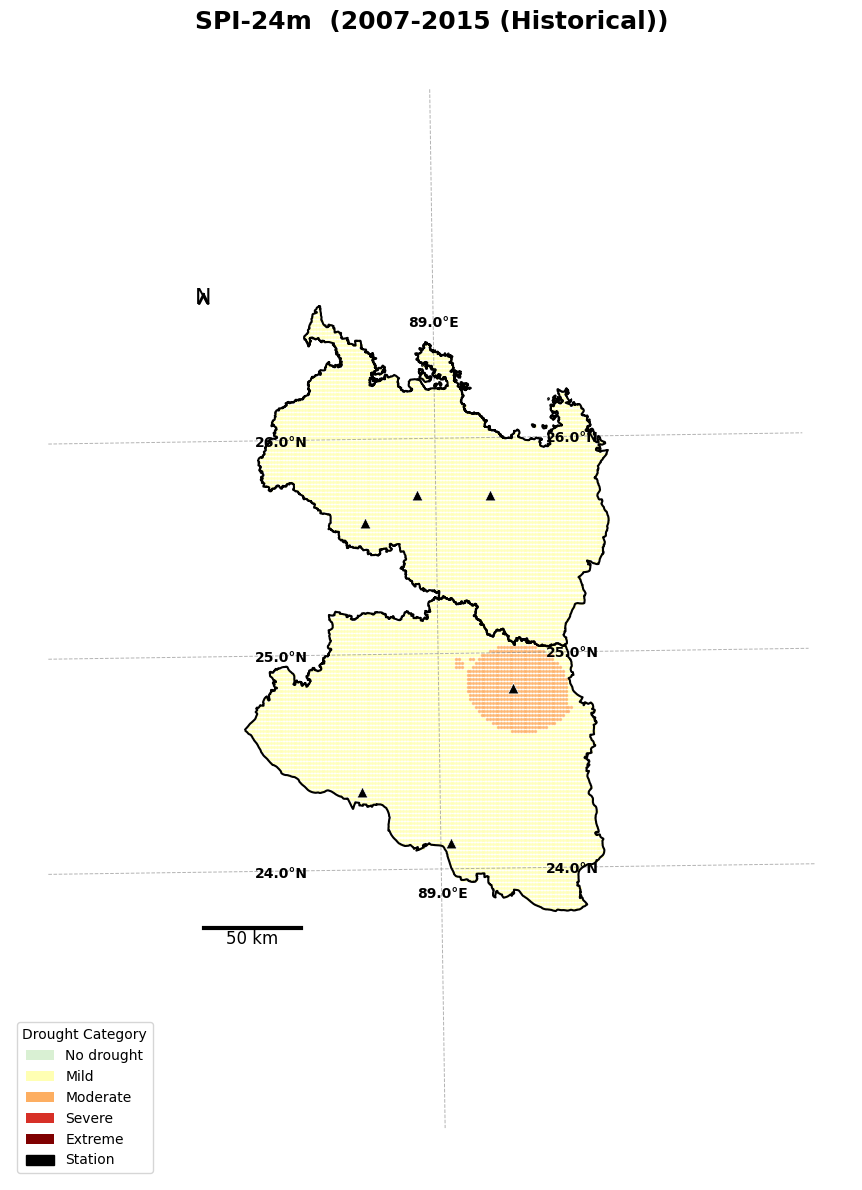

Saved: SPI_24m_2016-2023 (Historical - Recent).png


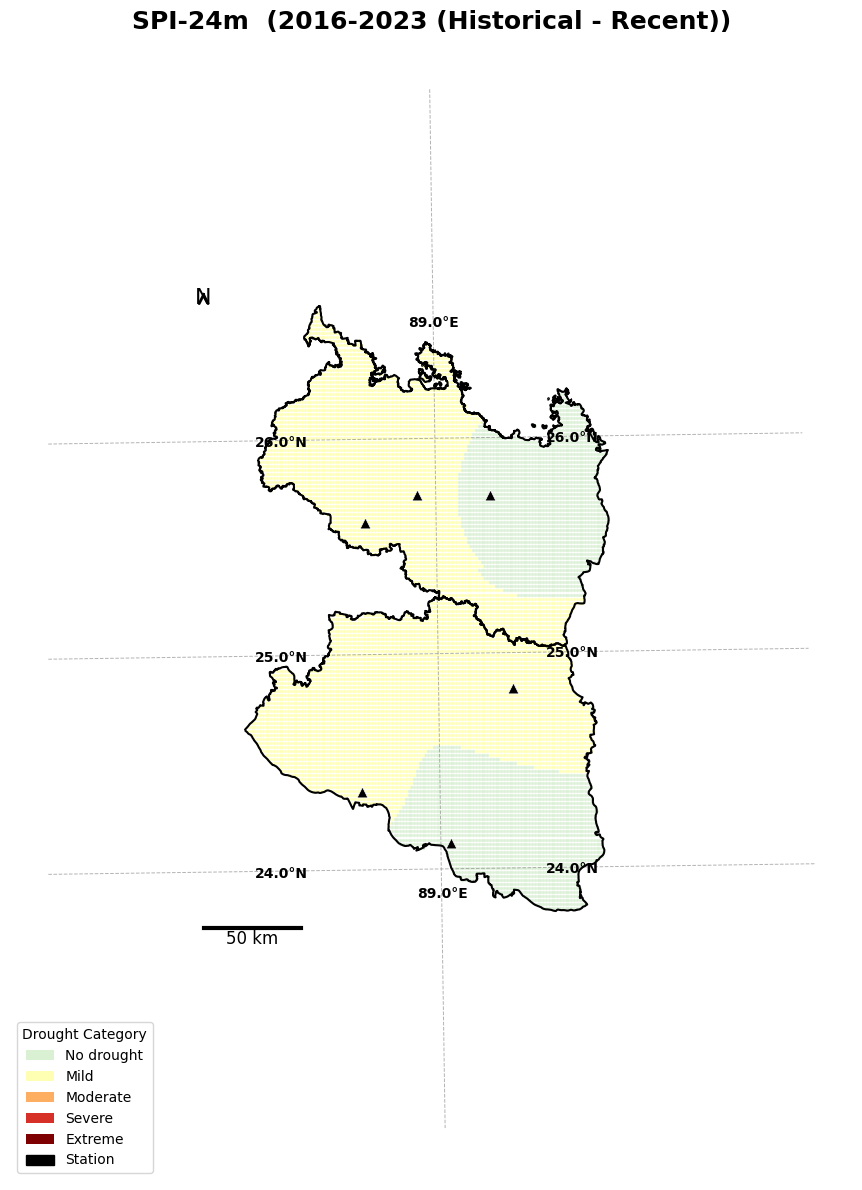

Saved: SPI_24m_2024-2050 (Forecast).png


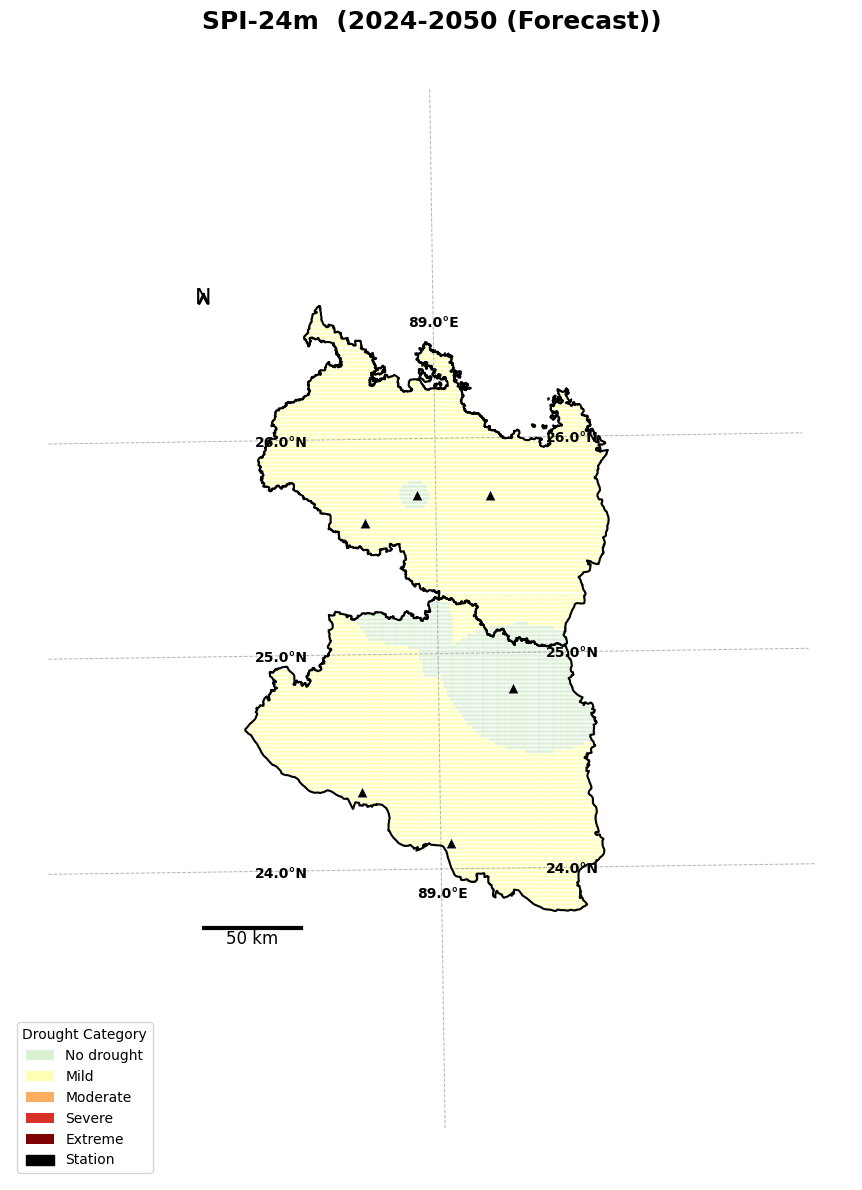

Saved: SPEI_24m_1998-2006 (Historical).png


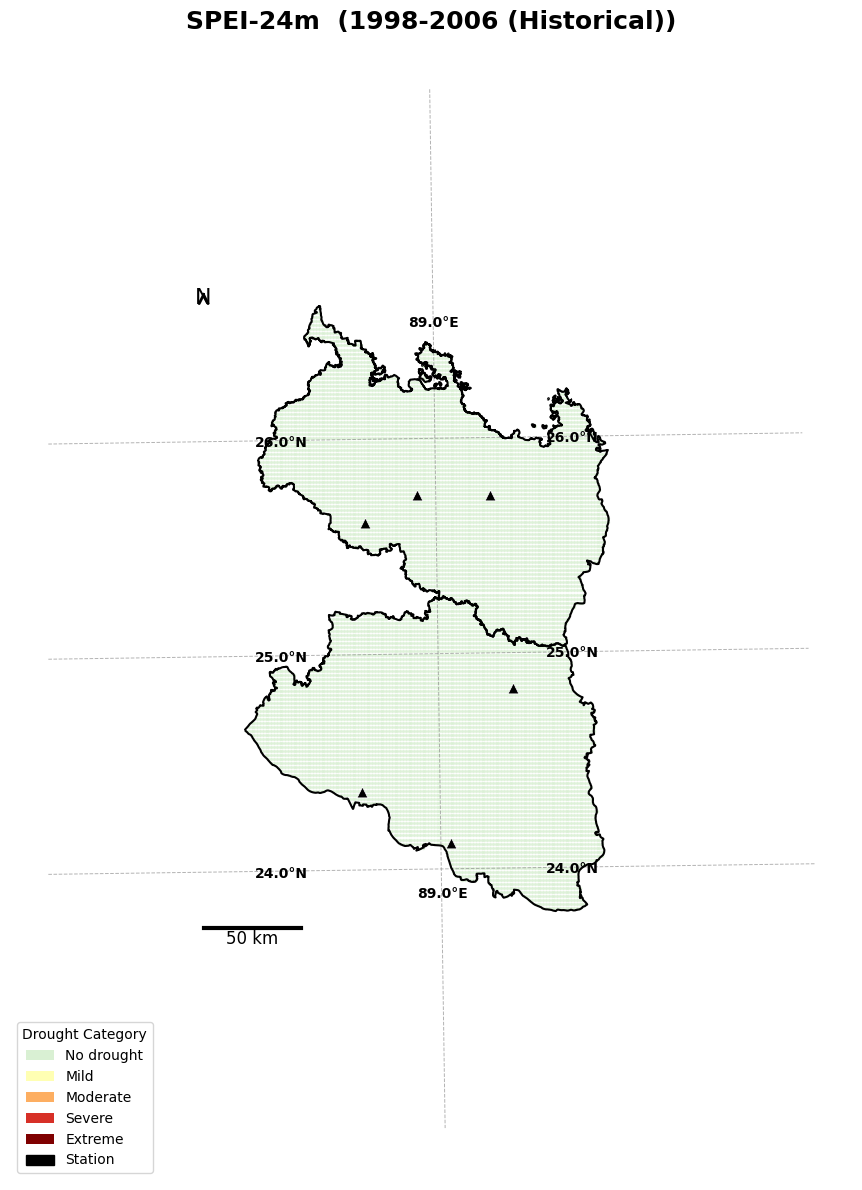

Saved: SPEI_24m_2007-2015 (Historical).png


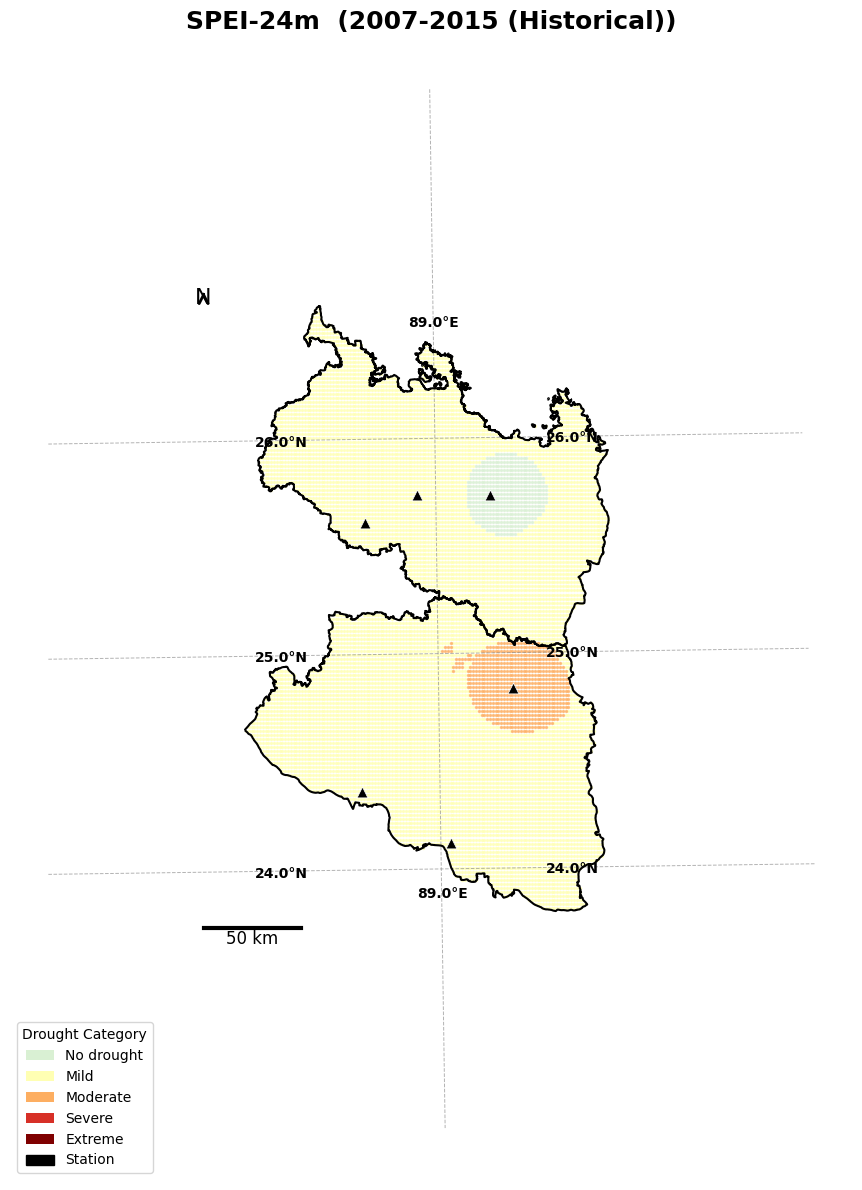

Saved: SPEI_24m_2016-2023 (Historical - Recent).png


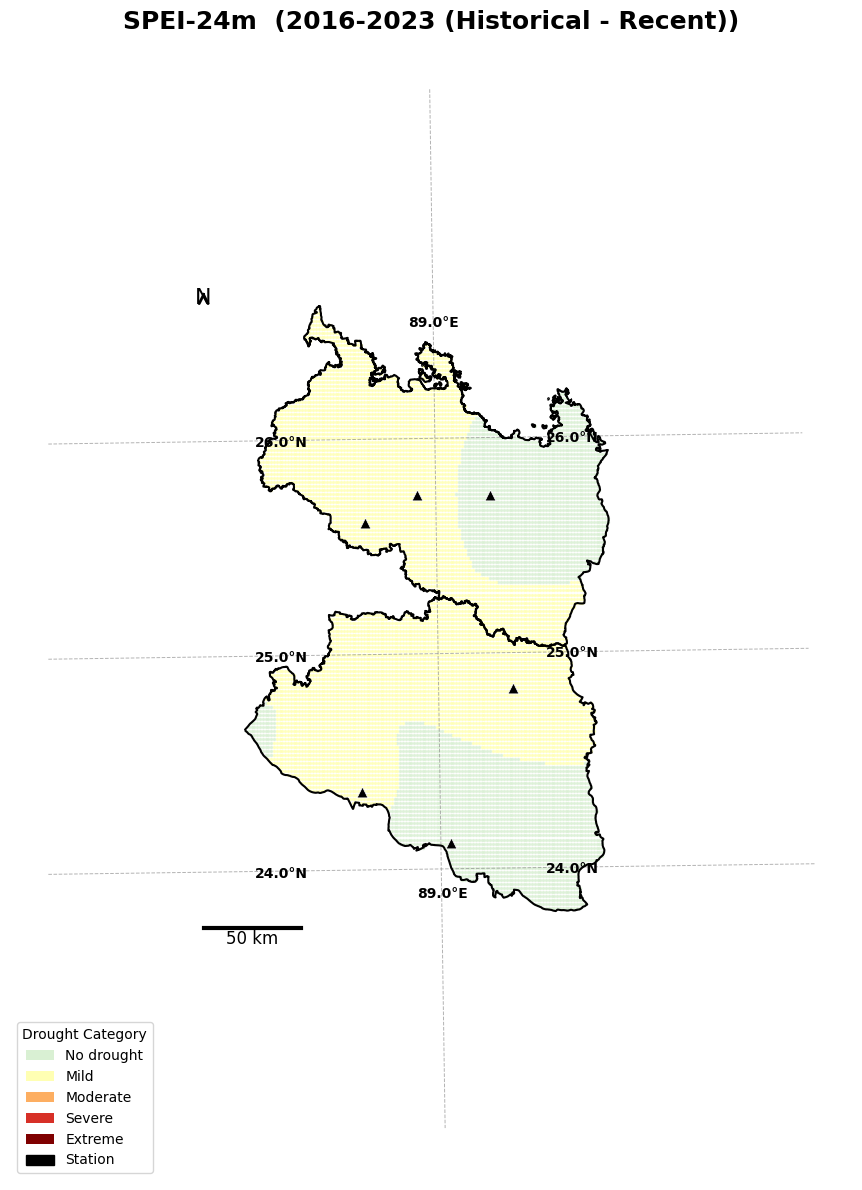

Saved: SPEI_24m_2024-2050 (Forecast).png


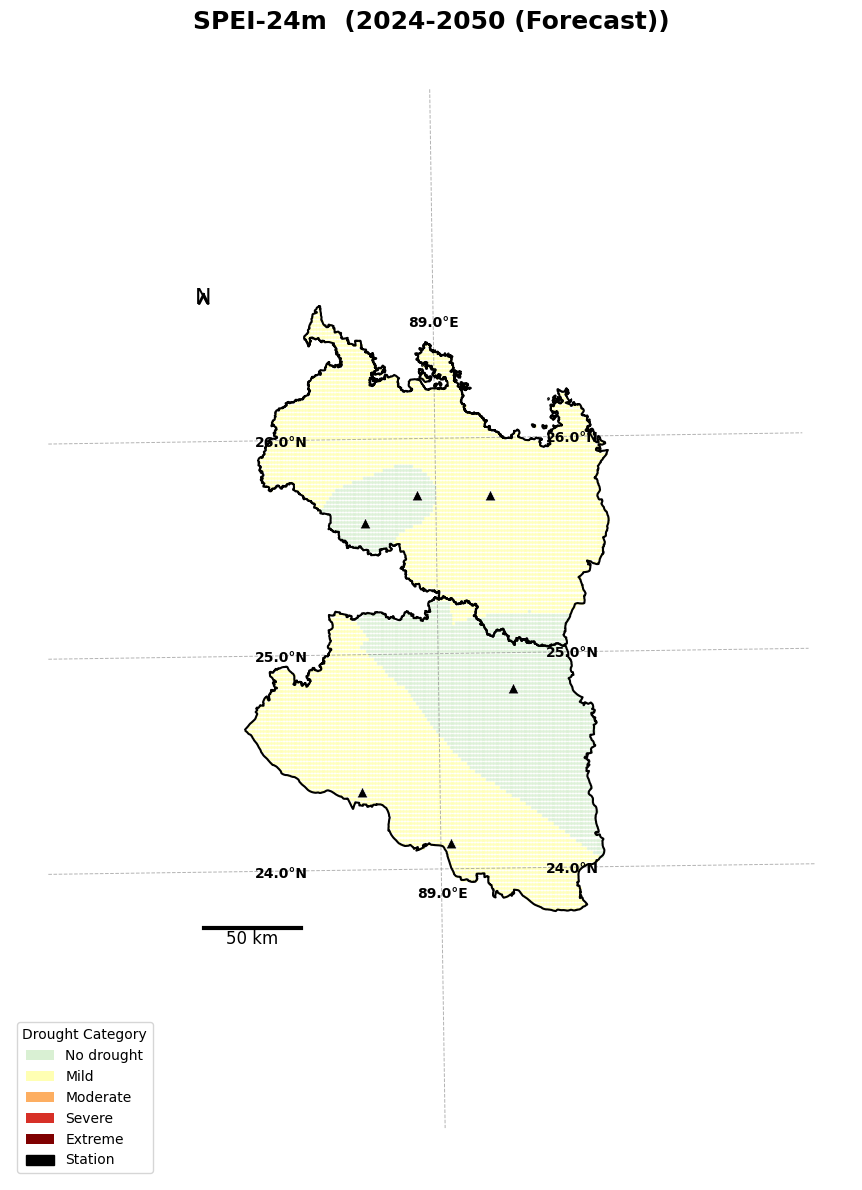

In [ ]:
# --- Single scale: 12 months only ---
periods = [
    '1998-2006 (Historical)',
    '2007-2015 (Historical)',
    '2016-2023 (Historical - Recent)',
    '2024-2050 (Forecast)'
]
period_labels = ['1998-2006', '2007-2015', '2016-2023', '2024-2050']
scales = [24]   # Change this to [1], [3], [6], or [24] as needed

for idx in ['SPI', 'SPEI']:
    for scale in scales:
        for period_label, period_full in zip(period_labels, periods):
            produce_drought_map(idx, scale, period_full, None, None)

**Step 5: (Optional) Overall hazard map**

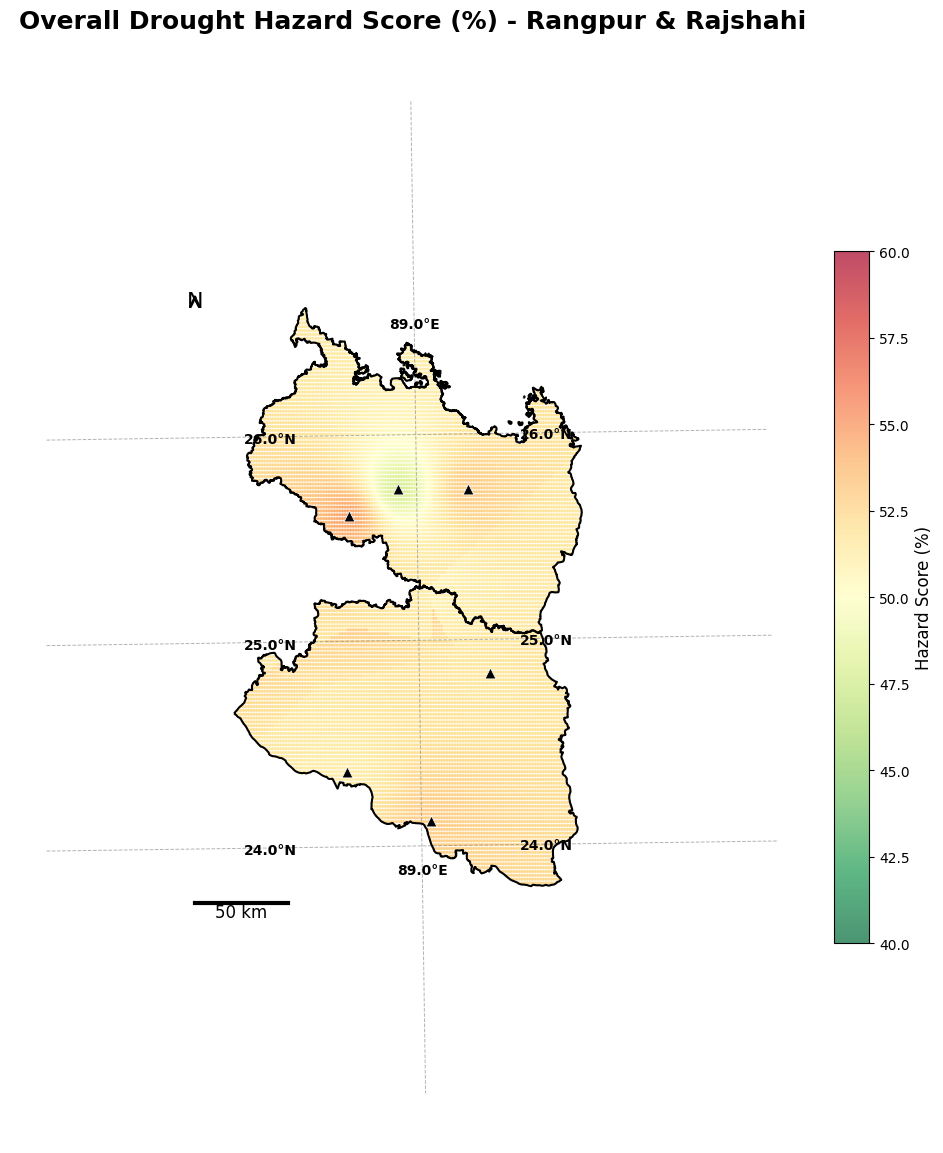

Saved: Overall_Hazard_Map_Rangpur_Rajshahi.png


In [ ]:
def produce_hazard_map():
    df_h = df_stations[['Station', 'Latitude', 'Longitude', 'Overall_Hazard_Score_%']].dropna()
    geometry = [Point(x, y) for x, y in zip(df_h['Longitude'], df_h['Latitude'])]
    gdf_h = gpd.GeoDataFrame(df_h, geometry=geometry, crs='EPSG:4326')
    gdf_h_proj = gdf_h.to_crs(crs_proj)

    points = np.array(gdf_h_proj.geometry.apply(lambda p: (p.x, p.y)).tolist())
    values = gdf_h_proj['Overall_Hazard_Score_%'].values

    # Use regional bounds for grid
    bounds = gdf_divisions_proj.total_bounds
    buffer = 50000
    xmin, ymin, xmax, ymax = bounds[0]-buffer, bounds[1]-buffer, bounds[2]+buffer, bounds[3]+buffer
    nx, ny = 200, 200
    grid_x, grid_y = np.meshgrid(np.linspace(xmin, xmax, nx), np.linspace(ymin, ymax, ny))
    grid_z = idw_interpolation(points, values, grid_x, grid_y, power=2, n_neighbors=3)

    grid_points = [Point(x, y) for x, y in zip(grid_x.ravel(), grid_y.ravel())]
    grid_gdf = gpd.GeoDataFrame(geometry=grid_points, crs=crs_proj)

    # Clip to Rangpur + Rajshahi
    mask_bd = grid_gdf[grid_gdf.intersects(combined_geom_proj)]
    coords = np.array(mask_bd.geometry.apply(lambda p: (p.x, p.y)).tolist())
    mask_bd['hazard'] = griddata((grid_x.ravel(), grid_y.ravel()), grid_z.ravel(),
                                 coords, method='nearest')

    fig, ax = plt.subplots(1, 1, figsize=(10, 12))

    # Draw Lat/Lon grid
    draw_lat_lon_grid(ax, gdf_divisions_proj, crs_proj)

    # Plot regional boundaries
    gdf_divisions_proj.boundary.plot(ax=ax, color='black', linewidth=1.5)

    # Scatter hazard data
    sc = ax.scatter(mask_bd.geometry.x, mask_bd.geometry.y, c=mask_bd['hazard'],
                    cmap='RdYlGn_r', s=2, alpha=0.7, vmin=40, vmax=60)
    gdf_h_proj.plot(ax=ax, color='black', marker='^', markersize=60,
                    edgecolor='white', linewidth=0.5, label='Station')

    ax.set_title('Overall Drought Hazard Score (%) - Rangpur & Rajshahi', fontsize=18, fontweight='bold')
    ax.axis('off')
    cbar = plt.colorbar(sc, ax=ax, shrink=0.6, pad=0.02)
    cbar.set_label('Hazard Score (%)', fontsize=12)

    # North arrow and scale bar
    x_arrow = xmin + 0.1 * (xmax - xmin)
    y_arrow = ymax - 0.1 * (ymax - ymin)
    ax.annotate('N', xy=(x_arrow, y_arrow), xytext=(x_arrow, y_arrow - 8000),
                arrowprops=dict(arrowstyle='->', lw=2, color='black'),
                ha='center', fontsize=16)
    scale_x = xmin + 0.1 * (xmax - xmin)
    scale_y = ymin + 0.1 * (ymax - ymin)
    ax.plot([scale_x, scale_x + 50000], [scale_y, scale_y], color='black', lw=3)
    ax.text(scale_x + 25000, scale_y - 8000, '50 km', ha='center', fontsize=12)

    plt.tight_layout()
    plt.savefig('Overall_Hazard_Map_Rangpur_Rajshahi.png', dpi=300, bbox_inches='tight')
    plt.show()
    print('Saved: Overall_Hazard_Map_Rangpur_Rajshahi.png')

produce_hazard_map()

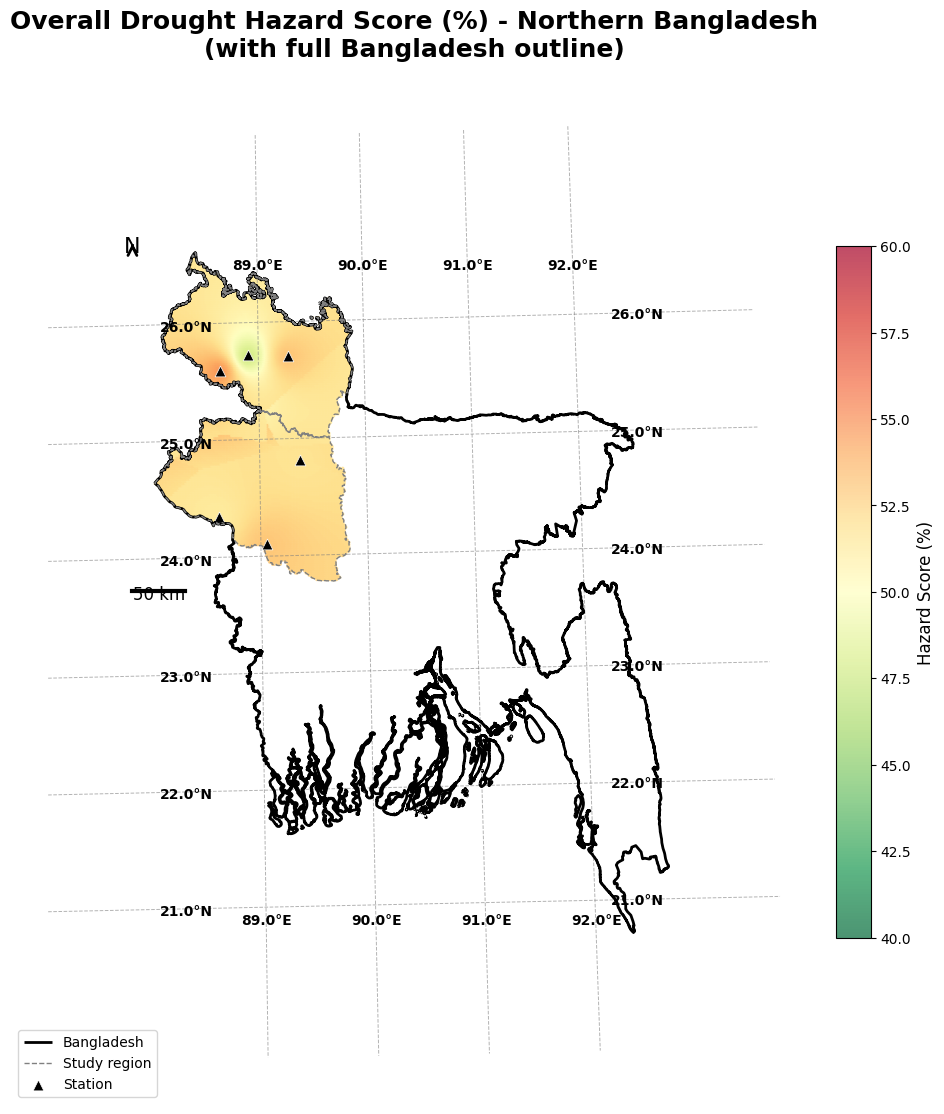

✅ Saved: Hazard_Map_Full_BD_Outline.png


In [ ]:
# =============================================================================
# EXTRA: Hazard Map with FULL Bangladesh outline + Lat/Lon across BD
# (Keeps your interpolated hazard layer & stations exactly as they are)
# =============================================================================

def produce_hazard_map_with_full_bd():
    # --- 1. Prepare the full Bangladesh country boundary ---
    # gdf_bgd was loaded in Step 2 (level 1 divisions). Dissolve to get country outline.
    gdf_country = gdf_bgd.dissolve()
    gdf_country_proj = gdf_country.to_crs(crs_proj)

    # --- 2. Prepare your hazard data (exactly as in your original Step 5) ---
    df_h = df_stations[['Station', 'Latitude', 'Longitude', 'Overall_Hazard_Score_%']].dropna()
    geometry = [Point(x, y) for x, y in zip(df_h['Longitude'], df_h['Latitude'])]
    gdf_h = gpd.GeoDataFrame(df_h, geometry=geometry, crs='EPSG:4326')
    gdf_h_proj = gdf_h.to_crs(crs_proj)

    points = np.array(gdf_h_proj.geometry.apply(lambda p: (p.x, p.y)).tolist())
    values = gdf_h_proj['Overall_Hazard_Score_%'].values

    # Interpolation grid (still based on the northern region bounds)
    bounds = gdf_divisions_proj.total_bounds
    buffer = 50000
    xmin, ymin, xmax, ymax = bounds[0]-buffer, bounds[1]-buffer, bounds[2]+buffer, bounds[3]+buffer
    nx, ny = 200, 200
    grid_x, grid_y = np.meshgrid(np.linspace(xmin, xmax, nx), np.linspace(ymin, ymax, ny))
    grid_z = idw_interpolation(points, values, grid_x, grid_y, power=2, n_neighbors=3)

    # Clip interpolation to the northern divisions (Rangpur + Rajshahi)
    grid_points = [Point(x, y) for x, y in zip(grid_x.ravel(), grid_y.ravel())]
    grid_gdf = gpd.GeoDataFrame(geometry=grid_points, crs=crs_proj)
    mask_bd = grid_gdf[grid_gdf.intersects(combined_geom_proj)]
    coords = np.array(mask_bd.geometry.apply(lambda p: (p.x, p.y)).tolist())
    mask_bd['hazard'] = griddata((grid_x.ravel(), grid_y.ravel()), grid_z.ravel(),
                                 coords, method='nearest')

    # --- 3. Plot ---
    fig, ax = plt.subplots(1, 1, figsize=(10, 12))

    # ----- A. Draw LAT/LON GRID for the FULL country -----
    # Get geographic bounds of the WHOLE country
    gdf_country_geo = gdf_country.to_crs('EPSG:4326')
    min_lon, min_lat, max_lon, max_lat = gdf_country_geo.total_bounds

    # Round to nearest integer for clean gridlines
    lats = np.arange(np.ceil(min_lat), np.floor(max_lat) + 1, 1)
    lons = np.arange(np.ceil(min_lon), np.floor(max_lon) + 1, 1)

    # Create full lat/lon lines spanning a wide area
    lines = []
    for lat in lats:
        lines.append(LineString([(min_lon - 1, lat), (max_lon + 1, lat)]))
    for lon in lons:
        lines.append(LineString([(lon, min_lat - 1), (lon, max_lat + 1)]))

    gdf_lines = gpd.GeoDataFrame(geometry=lines, crs='EPSG:4326').to_crs(crs_proj)
    gdf_lines.plot(ax=ax, color='gray', linestyle='--', linewidth=0.7, alpha=0.6)

    # Get projected bounds for label placement
    pxmin, pymin, pxmax, pymax = gdf_country_proj.total_bounds

    # Latitude labels (left & right edges)
    for lat in lats:
        p = Point(min_lon, lat)
        p_proj = gpd.GeoSeries([p], crs='EPSG:4326').to_crs(crs_proj).iloc[0]
        ax.text(pxmin + 5000, p_proj.y, f'{lat}°N', ha='left', va='center', fontsize=10, fontweight='bold')
        p = Point(max_lon, lat)
        p_proj = gpd.GeoSeries([p], crs='EPSG:4326').to_crs(crs_proj).iloc[0]
        ax.text(pxmax - 5000, p_proj.y, f'{lat}°N', ha='right', va='center', fontsize=10, fontweight='bold')

    # Longitude labels (bottom & top edges)
    for lon in lons:
        p = Point(lon, min_lat)
        p_proj = gpd.GeoSeries([p], crs='EPSG:4326').to_crs(crs_proj).iloc[0]
        ax.text(p_proj.x, pymin + 5000, f'{lon}°E', ha='center', va='bottom', fontsize=10, fontweight='bold')
        p = Point(lon, max_lat)
        p_proj = gpd.GeoSeries([p], crs='EPSG:4326').to_crs(crs_proj).iloc[0]
        ax.text(p_proj.x, pymax - 5000, f'{lon}°E', ha='center', va='top', fontsize=10, fontweight='bold')

    # ----- B. Plot FULL country boundary (thick black) -----
    gdf_country_proj.boundary.plot(ax=ax, color='black', linewidth=2, label='Bangladesh')

    # ----- C. Plot northern DIVISIONS boundary (grey dashed, for reference) -----
    gdf_divisions_proj.boundary.plot(ax=ax, color='gray', linewidth=1, linestyle='--', label='Study region')

    # ----- D. Plot your hazard layer (clipped to northern divisions) -----
    sc = ax.scatter(mask_bd.geometry.x, mask_bd.geometry.y, c=mask_bd['hazard'],
                    cmap='RdYlGn_r', s=2, alpha=0.7, vmin=40, vmax=60)

    # ----- E. Plot stations -----
    gdf_h_proj.plot(ax=ax, color='black', marker='^', markersize=60,
                    edgecolor='white', linewidth=0.5, label='Station')

    # Title, colorbar, north arrow, scale bar
    ax.set_title('Overall Drought Hazard Score (%) - Northern Bangladesh\n(with full Bangladesh outline)',
                 fontsize=18, fontweight='bold')
    ax.axis('off')

    cbar = plt.colorbar(sc, ax=ax, shrink=0.6, pad=0.02)
    cbar.set_label('Hazard Score (%)', fontsize=12)

    # North arrow (based on northern region bounds – you can also use country bounds)
    x_arrow = xmin + 0.1 * (xmax - xmin)
    y_arrow = ymax - 0.1 * (ymax - ymin)
    ax.annotate('N', xy=(x_arrow, y_arrow), xytext=(x_arrow, y_arrow - 8000),
                arrowprops=dict(arrowstyle='->', lw=2, color='black'),
                ha='center', fontsize=16)

    # Scale bar (50 km)
    scale_x = xmin + 0.1 * (xmax - xmin)
    scale_y = ymin + 0.1 * (ymax - ymin)
    ax.plot([scale_x, scale_x + 50000], [scale_y, scale_y], color='black', lw=3)
    ax.text(scale_x + 25000, scale_y - 8000, '50 km', ha='center', fontsize=12)

    # Legend (simple – you can add custom handles if needed)
    ax.legend(loc='lower left', fontsize=10)

    plt.tight_layout()
    plt.savefig('Hazard_Map_Full_BD_Outline.png', dpi=300, bbox_inches='tight')
    plt.show()
    print('✅ Saved: Hazard_Map_Full_BD_Outline.png')

# Run it
produce_hazard_map_with_full_bd()

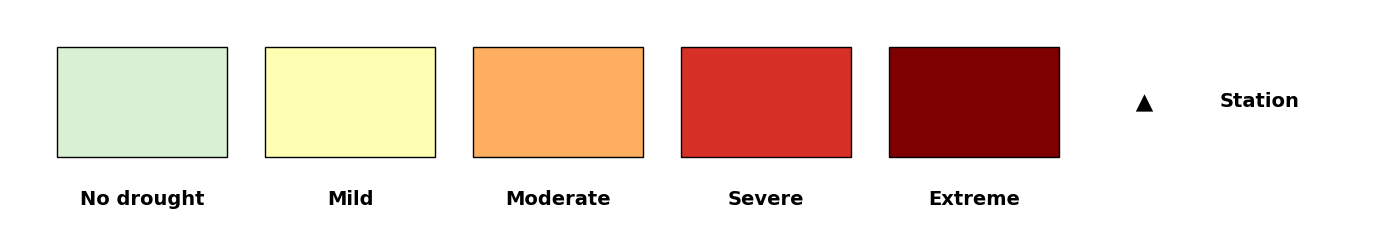

✅ Saved: Drought_Legend_Horizontal.png


In [ ]:
# =============================================================================
# EXTRA: Generate a standalone horizontal/landscape drought legend
# (Perfect for putting beside your maps in the paper)
# =============================================================================

def create_horizontal_legend():
    fig, ax = plt.subplots(1, 1, figsize=(14, 2.5))
    ax.axis('off')

    categories = ['No drought', 'Mild', 'Moderate', 'Severe', 'Extreme']
    colors = ['#d9f0d3', '#ffffb3', '#fdae61', '#d73027', '#7f0000']

    # Horizontal colour swatches
    for i, (cat, col) in enumerate(zip(categories, colors)):
        rect = Rectangle((i * 2.2, 0.6), 1.8, 0.9, facecolor=col, edgecolor='black', linewidth=1)
        ax.add_patch(rect)
        ax.text(i * 2.2 + 0.9, 0.25, cat, ha='center', va='center', fontsize=14, fontweight='bold')

    # Station marker (triangle)
    ax.scatter(11.5, 1.05, color='black', marker='^', s=200, edgecolor='white', linewidth=1)
    ax.text(12.3, 1.05, 'Station', ha='left', va='center', fontsize=14, fontweight='bold')

    # Set limits
    ax.set_xlim(-0.5, 14)
    ax.set_ylim(0, 1.8)

    plt.tight_layout()
    plt.savefig('Drought_Legend_Horizontal.png', dpi=300, bbox_inches='tight')
    plt.show()
    print('✅ Saved: Drought_Legend_Horizontal.png')

create_horizontal_legend()

In [ ]:
import zipfile
import os

# Remove old zip if it exists (to avoid appending errors)
if os.path.exists('all_drought_maps_Update.zip'):
    os.remove('all_drought_maps_Update.zip')

# Create a new zip file
with zipfile.ZipFile('all_drought_maps_Update.zip', 'w') as zipf:
    for f in os.listdir():
        if f.endswith('.png'):
            zipf.write(f)
            print(f'Added: {f}')

print('✅ all_drought_maps_Update.zip created successfully!')

Added: SPI_3m_2024-2050 (Forecast).png
Added: SPI_6m_2024-2050 (Forecast).png
Added: SPEI_24m_1998-2006 (Historical).png
Added: SPEI_3m_1998-2006 (Historical).png
Added: SPI_1m_1998-2006 (Historical).png
Added: SPI_3m_2016-2023 (Historical - Recent).png
Added: SPI_12m_1998-2006 (Historical).png
Added: SPEI_1m_2024-2050 (Forecast).png
Added: SPI_24m_2007-2015 (Historical).png
Added: SPI_12m_2007-2015 (Historical).png
Added: SPI_1m_2024-2050 (Forecast).png
Added: SPEI_12m_2024-2050 (Forecast).png
Added: SPEI_6m_2024-2050 (Forecast).png
Added: SPI_24m_1998-2006 (Historical).png
Added: SPI_3m_1998-2006 (Historical).png
Added: SPEI_12m_1998-2006 (Historical).png
Added: SPI_6m_1998-2006 (Historical).png
Added: SPEI_6m_1998-2006 (Historical).png
Added: SPI_6m_2007-2015 (Historical).png
Added: SPI_12m_2024-2050 (Forecast).png
Added: SPI_24m_2016-2023 (Historical - Recent).png
Added: SPEI_12m_2016-2023 (Historical - Recent).png
Added: SPEI_3m_2016-2023 (Historical - Recent).png
Added: SPEI_3m_2

In [ ]:
from google.colab import files

# Force download the zip file directly
files.download('all_drought_maps_Update.zip')

print('✅ Download started! Check your browser’s download folder.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Download started! Check your browser’s download folder.
